<a href="https://colab.research.google.com/github/BeepTan/Final-Year-Project/blob/main/Another_copy_of_Untitled37v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision torchmetrics pycocotools matplotlib seaborn torch-pruning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.2/70.2 kB 9.4 MB/s eta 0:00:00


In [ ]:
# ── Imports ──────────────────────────────────────────────────────────
import os, time, copy, random, sys
import csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from collections import defaultdict, OrderedDict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.quantization
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms.functional as TF
from torchvision.models import (
    efficientnet_v2_l,
    mobilenet_v3_large,
    EfficientNet_V2_L_Weights,
    MobileNet_V3_Large_Weights,
)
from torchvision.models.detection import (
    FasterRCNN,
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights,
)
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.ops import box_iou, MultiScaleRoIAlign

from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

try:
    import torch_pruning as tp
except ImportError:
    tp = None


In [ ]:
# ── Device ───────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Using device: cuda
GPU: NVIDIA L4


In [ ]:
# CONFIG
# ═══════════════════════════════════════════════════════════════════
CONFIG = {
    # Dataset
    'data_dir':           '/content/drive/MyDrive/Dataset-busi-split',
    'img_size':           (224, 224),
    'batch_size':         16,
    'num_workers':        2,
    'seed':               42,

    # Base training
    'num_epochs':         30,
    'lr':                 1e-4,
    'weight_decay':       0.0005,
    'step_size':          15,
    'gamma':              0.5,
    'freeze_backbone':    False,

    # Fine-tune (normal model — no pruning)
    'ft_normal_epochs':   10,
    'ft_normal_lr':       5e-5,

    # Fine-tune (pruned model)
    'ft_pruned_epochs':   10,
    'ft_pruned_lr':       1e-4,

    # Inference
    'score_threshold':    0.5,

    # Pruning
    'prune_ratio':        0.7,
    'hybrid_alpha':       0.5,   # activation score weight
    'hybrid_beta':        0.5,   # Taylor/gradient score weight
    'xai_prune_num_visual_filters': 6,
    'use_structural_pruning': False,
    'structural_pruning_backbones': [],
    'ablation_backbone': 'resnet50_fpn',
    'ablation_backbone_label': 'ResNet50-FPN',

    # Output
    'save_dir':           '/content/drive/MyDrive/FYP5V4_resnet50_ablation/checkpoints',
    'gradcam_dir':        '/content/drive/MyDrive/FYP5V4_resnet50_ablation/gradcam_outputs',
    'plot_dir':           '/content/drive/MyDrive/FYP5V4_resnet50_ablation/plots',
    'log_dir':            '/content/drive/MyDrive/FYP5V4_resnet50_ablation/logs',

    # Speed benchmark
    'speed_runs':         50,   # number of forward passes to average
}

os.makedirs(CONFIG['save_dir'],    exist_ok=True)
os.makedirs(CONFIG['gradcam_dir'], exist_ok=True)
os.makedirs(CONFIG['plot_dir'],    exist_ok=True)
os.makedirs(CONFIG['log_dir'],     exist_ok=True)
print('Config ready.')


class TeeLogger:
    def __init__(self, *streams):
        self.streams = streams

    def write(self, data):
        for stream in self.streams:
            stream.write(data)
            stream.flush()

    def flush(self):
        for stream in self.streams:
            stream.flush()


def start_terminal_logging(log_dir=CONFIG['log_dir']):
    os.makedirs(log_dir, exist_ok=True)
    timestamp = time.strftime('%Y%m%d_%H%M%S')
    log_path = os.path.join(log_dir, f'training_terminal_{timestamp}.txt')
    log_file = open(log_path, 'w', encoding='utf-8')
    current_stdout = sys.stdout
    current_stderr = sys.stderr
    sys.stdout = TeeLogger(current_stdout, log_file)
    sys.stderr = TeeLogger(current_stderr, log_file)
    print(f'Terminal output will be saved to: {log_path}')
    return log_path


def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = CONFIG['seed'] + worker_id
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    torch.manual_seed(worker_seed)


set_seed(CONFIG['seed'])
print(f'Reproducibility seed set to {CONFIG["seed"]}.')

Config ready.
Reproducibility seed set to 42.


In [ ]:
# DATASET
# ═══════════════════════════════════════════════════════════════════
class BUSIDetectionDataset(Dataset):
    """
    Loads BUSI images + their segmentation masks.
    Generates bounding boxes from masks automatically.

    Expected folder structure (per split):
        Dataset-busi/train/benign/
            benign (1).png
            benign (1)_mask.png
            benign (1)_mask_1.png
            ...
    """

    CLASS_MAP = {'benign': 1, 'malignant': 2, 'normal': 3}

    def __init__(self, root_dir, split='train', img_size=(224, 224), use_augmentation=False):
        self.root_dir = os.path.join(root_dir, split)
        self.img_size = img_size
        self.use_augmentation = use_augmentation
        self.samples = []

        if not os.path.isdir(self.root_dir):
            print(f'  [{split}] Split folder not found: {self.root_dir}')

        for class_name in ['benign', 'malignant', 'normal']:
            class_dir = os.path.join(self.root_dir, class_name)
            if not os.path.isdir(class_dir):
                print(f'  [{split}] Class folder not found: {class_dir}')
                continue

            all_files  = sorted(os.listdir(class_dir))
            image_files = [f for f in all_files
                           if f.endswith(('.png', '.jpg', '.jpeg'))
                           and '_mask' not in f]

            for img_file in image_files:
                img_path  = os.path.join(class_dir, img_file)
                base_name = os.path.splitext(img_file)[0]
                mask_files = [f for f in all_files
                              if f.startswith(base_name) and '_mask' in f]
                mask_paths = [os.path.join(class_dir, mf) for mf in mask_files]
                self.samples.append((img_path, self.CLASS_MAP[class_name], mask_paths))

        print(f'  [{split}] Loaded {len(self.samples)} images '
              f'({sum(1 for s in self.samples if len(s[2]) > 0)} with masks)')

    def __len__(self):
        return len(self.samples)

    def _get_bboxes_from_mask(self, mask_path, orig_w, orig_h):
        mask   = Image.open(mask_path).convert('L')
        mask   = np.array(mask)
        binary = (mask > 127).astype(np.uint8)
        coords = np.argwhere(binary > 0)
        if len(coords) == 0:
            return None
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        if x_max <= x_min or y_max <= y_min:
            return None
        return [x_min, y_min, x_max, y_max]

    def __getitem__(self, idx):
        img_path, class_label, mask_paths = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        orig_w, orig_h = image.size

        boxes, labels = [], []
        for mp in mask_paths:
            bbox = self._get_bboxes_from_mask(mp, orig_w, orig_h)
            if bbox is not None:
                boxes.append(bbox)
                labels.append(class_label)

        if len(boxes) == 0:
            boxes.append([0, 0, orig_w - 1, orig_h - 1])
            labels.append(class_label)

        image   = image.resize(self.img_size)
        scale_x = self.img_size[0] / orig_w
        scale_y = self.img_size[1] / orig_h

        scaled_boxes = [
            [b[0]*scale_x, b[1]*scale_y, b[2]*scale_x, b[3]*scale_y]
            for b in boxes
        ]

        boxes_tensor  = torch.as_tensor(scaled_boxes, dtype=torch.float32)
        labels_tensor = torch.as_tensor(labels,       dtype=torch.int64)

        if self.use_augmentation and torch.rand(1) < 0.5:
            image = TF.hflip(image)
            w = self.img_size[0]
            boxes_tensor[:, [0, 2]] = w - boxes_tensor[:, [2, 0]]

        image = TF.to_tensor(image)

        target = {
            'boxes':    boxes_tensor,
            'labels':   labels_tensor,
            'image_id': torch.tensor([idx]),
            'area':     (boxes_tensor[:, 3] - boxes_tensor[:, 1]) *
                        (boxes_tensor[:, 2] - boxes_tensor[:, 0]),
            'iscrowd':  torch.zeros(len(labels), dtype=torch.int64),
        }
        return image, target


def collate_fn(batch):
    return tuple(zip(*batch))


def validate_busi_dataset(train_dataset, val_dataset, test_dataset, data_dir):
    split_counts = {
        'train': len(train_dataset),
        'val': len(val_dataset),
        'test': len(test_dataset),
    }
    missing = [split for split, count in split_counts.items() if count == 0]
    if missing:
        expected = os.path.join(data_dir, '<split>', '<class>', 'image.png')
        raise ValueError(
            'BUSI dataset loading failed because one or more splits have 0 images: '
            f'{split_counts}.\n'
            f'Current CONFIG["data_dir"]: {data_dir}\n'
            f'Expected structure: {expected}\n'
            'Check that Google Drive is mounted, CONFIG["data_dir"] points to the folder '
            'that contains train/val/test, and class folders are named benign, malignant, normal.'
        )


def load_busi_data(
    data_dir      = CONFIG['data_dir'],
    img_size      = CONFIG['img_size'],
    batch_size    = CONFIG['batch_size'],
    use_augmentation = True,
    num_workers   = CONFIG['num_workers']
):
    print('Loading BUSI Detection Dataset...')
    train_dataset = BUSIDetectionDataset(data_dir, 'train', img_size, use_augmentation=use_augmentation)
    val_dataset   = BUSIDetectionDataset(data_dir, 'val',   img_size, use_augmentation=False)
    test_dataset  = BUSIDetectionDataset(data_dir, 'test',  img_size, use_augmentation=False)
    validate_busi_dataset(train_dataset, val_dataset, test_dataset, data_dir)

    train_generator = torch.Generator()
    train_generator.manual_seed(CONFIG['seed'])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, collate_fn=collate_fn, pin_memory=True,
                              worker_init_fn=seed_worker, generator=train_generator)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, collate_fn=collate_fn, pin_memory=True,
                              worker_init_fn=seed_worker)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, collate_fn=collate_fn, pin_memory=True,
                              worker_init_fn=seed_worker)

    CLASS_NAMES = ['__background__', 'benign', 'malignant', 'normal']
    print(f'Classes: {CLASS_NAMES}')
    print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}')
    return train_loader, val_loader, test_loader, CLASS_NAMES


train_loader, val_loader, test_loader, CLASS_NAMES = load_busi_data()
NUM_CLASSES = len(CLASS_NAMES)   # 4 (background + 3)

Loading BUSI Detection Dataset...
  [train] Loaded 545 images (545 with masks)
  [val] Loaded 115 images (115 with masks)
  [test] Loaded 120 images (120 with masks)
Classes: ['__background__', 'benign', 'malignant', 'normal']
Train: 545 | Val: 115 | Test: 120


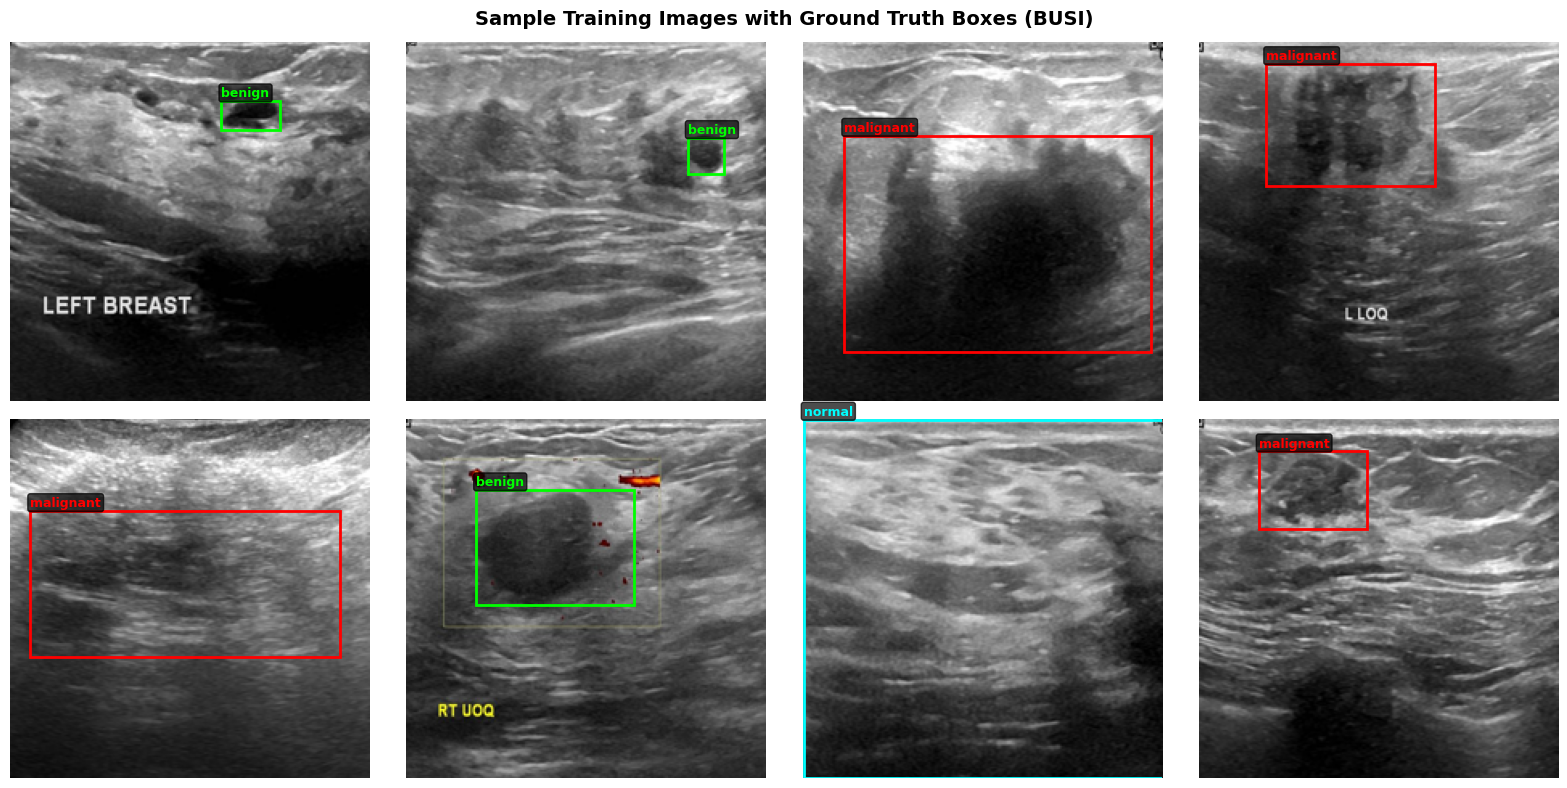

In [ ]:
# ─── Preview ─────────────────────────────────────────────────────────
def preview_detections(data_loader, class_names, num_images=8):
    images, targets = next(iter(data_loader))
    cols = 4
    rows = (min(num_images, len(images)) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    fig.suptitle('Sample Training Images with Ground Truth Boxes (BUSI)',
                 fontsize=14, fontweight='bold')
    axes = axes.flatten() if rows > 1 else [axes] if rows == 1 and cols == 1 else axes.flatten()
    colors = {1: 'lime', 2: 'red', 3: 'cyan'}

    for i in range(min(num_images, len(images))):
        img = images[i].permute(1, 2, 0).clamp(0, 1).numpy()
        ax  = axes[i]
        ax.imshow(img)
        for box, label in zip(targets[i]['boxes'], targets[i]['labels']):
            x1, y1, x2, y2 = box.tolist()
            lbl   = label.item()
            color = colors.get(lbl, 'white')
            rect  = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=2, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1 - 3, class_names[lbl],
                    color=color, fontsize=9, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
        ax.axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()


preview_detections(train_loader, CLASS_NAMES)


In [ ]:

# MODEL
# ═══════════════════════════════════════════════════════════════════
class CustomFastRCNNPredictor(nn.Module):
    def __init__(self, in_features, num_classes, dropout_p=0.3):
        super().__init__()
        self.dropout = nn.Dropout(dropout_p)
        self.cls_score = nn.Linear(in_features, num_classes)
        self.bbox_pred = nn.Linear(in_features, num_classes * 4)

    def forward(self, x):
        if x.dim() == 4:
            assert list(x.shape[2:]) == [1, 1]
        x = x.flatten(start_dim=1)
        x = self.dropout(x)
        scores = self.cls_score(x)
        bbox_deltas = self.bbox_pred(x)
        return scores, bbox_deltas


class SingleScaleBackbone(nn.Module):
    def __init__(self, body, out_channels):
        super().__init__()
        self.body = body
        self.out_channels = out_channels

    def forward(self, x):
        return OrderedDict([('0', self.body(x))])


def _build_single_scale_fasterrcnn(backbone_body, out_channels, num_classes):
    backbone = SingleScaleBackbone(backbone_body, out_channels)
    anchor_generator = AnchorGenerator(
        sizes=((32, 64, 128, 256, 512),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )
    roi_pooler = MultiScaleRoIAlign(
        featmap_names=['0'],
        output_size=7,
        sampling_ratio=2
    )
    model = FasterRCNN(
        backbone,
        num_classes=num_classes,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        min_size=CONFIG['img_size'][1],
        max_size=CONFIG['img_size'][1],
    )
    return model


def build_detection_model(backbone_name, num_classes, freeze_backbone=CONFIG['freeze_backbone']):
    if backbone_name == 'resnet50_fpn':
        model = fasterrcnn_resnet50_fpn(
            weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
            min_size=CONFIG['img_size'][1],
            max_size=CONFIG['img_size'][1],
        )
    elif backbone_name == 'mobilenetv3_large':
        mobile_features = mobilenet_v3_large(
            weights=MobileNet_V3_Large_Weights.DEFAULT
        ).features
        model = _build_single_scale_fasterrcnn(
            mobile_features,
            mobile_features[-1][0].out_channels,
            num_classes
        )
    elif backbone_name == 'efficientnetv2_l':
        eff_features = efficientnet_v2_l(
            weights=EfficientNet_V2_L_Weights.DEFAULT
        ).features
        model = _build_single_scale_fasterrcnn(
            eff_features,
            eff_features[-1][0].out_channels,
            num_classes
        )
    else:
        raise ValueError(f'Unsupported backbone: {backbone_name}')

    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = CustomFastRCNNPredictor(in_features, num_classes)
    if freeze_backbone:
        for param in model.backbone.parameters():
            param.requires_grad = False
        print('  Backbone frozen.')
    model.backbone_name = backbone_name
    return model


def raw_param_count(m):
    return sum(p.numel() for p in m.parameters())


def count_params(m):
    return getattr(m, '_effective_num_params', raw_param_count(m))


def get_model_device(model):
    try:
        return next(model.parameters()).device
    except StopIteration:
        return device


def get_model_file_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024) if path and os.path.exists(path) else 0.0


def save_metrics_csv(rows, path):
    if not rows:
        return
    os.makedirs(os.path.dirname(path), exist_ok=True)
    fieldnames = sorted({key for row in rows for key in row.keys()})
    with open(path, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)
    print(f'Metrics CSV saved -> {path}')


def print_model_summary(model, label='Model'):
    total     = count_params(model)
    raw_total = raw_param_count(model)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{'=' * 55}")
    print(f"  {label}")
    print(f"  Effective params: {total:,}")
    if total != raw_total:
        print(f"  Raw params:       {raw_total:,}")
    else:
        print(f"  Total params:     {raw_total:,}")
    print(f"  Trainable params: {trainable:,}")
    print(f"  Frozen params:    {raw_total - trainable:,}")
    print(f"{'=' * 55}")


In [ ]:
# TRAINING LOOP (shared by base, fine-tune normal, fine-tune pruned)
# ═══════════════════════════════════════════════════════════════════
def train_model(
    model, train_loader, val_loader,
    num_epochs  = CONFIG['num_epochs'],
    lr          = CONFIG['lr'],
    weight_decay= CONFIG['weight_decay'],
    step_size   = CONFIG['step_size'],
    gamma       = CONFIG['gamma'],
    save_dir    = CONFIG['save_dir'],
    tag         = 'model'
):
    """
    Train / fine-tune Faster R-CNN.
    tag: short label used in checkpoint filenames.
    """
    optimizer = Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=gamma, patience=5
    )

    history = {'train_loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    best_weights  = copy.deepcopy(model.state_dict())

    print(f'\nTraining [{tag}] for {num_epochs} epochs on {device}...\n' + '=' * 60)

    for epoch in range(1, num_epochs + 1):
        start = time.time()

        # ── Train ────────────────────────────────────────────────────
        model.train()
        epoch_loss, num_batches = 0.0, 0
        for images, targets in train_loader:
            images  = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            loss_dict = model(images, targets)
            losses    = sum(loss for loss in loss_dict.values())
            optimizer.zero_grad()
            losses.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            if hasattr(model, '_apply_prune_masks'):
                model._apply_prune_masks()
            epoch_loss  += losses.item()
            num_batches += 1
        train_loss = epoch_loss / num_batches

        # ── Validation ───────────────────────────────────────────────
        model.train()   # Faster R-CNN needs train mode to compute losses
        val_loss_total, val_batches = 0.0, 0
        with torch.no_grad():
            for images, targets in val_loader:
                images  = [img.to(device) for img in images]
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
                loss_dict = model(images, targets)
                losses    = sum(loss for loss in loss_dict.values())
                val_loss_total += losses.item()
                val_batches    += 1
        val_loss = val_loss_total / val_batches
        elapsed  = time.time() - start

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        scheduler.step(val_loss)

        is_best = val_loss < best_val_loss
        print(f'Epoch [{epoch:02d}/{num_epochs}]  '
              f'Train: {train_loss:.4f}  Val: {val_loss:.4f}  '
              f'Time: {elapsed:.1f}s'
              + (' ✓ Best' if is_best else ''))
        if is_best:
            best_val_loss = val_loss
            best_weights  = copy.deepcopy(model.state_dict())
            torch.save(best_weights, f'{save_dir}/best_{tag}_epoch{epoch}.pth')

    model.load_state_dict(best_weights)
    if hasattr(model, '_apply_prune_masks'):
        model._apply_prune_masks()
    print(f'\n✓ [{tag}] done.  Best Val Loss: {best_val_loss:.4f}')
    return model, history


def plot_history(history, title='Training History', save_dir=CONFIG['plot_dir']):
    os.makedirs(save_dir, exist_ok=True)
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(figsize=(9, 4))
    fig.suptitle(title, fontsize=13, fontweight='bold')
    ax.plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
    ax.plot(epochs_range, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Total Loss')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    safe_title = title.replace(' ', '_').replace('—', '').lower()
    fig_path = os.path.join(save_dir, f'{safe_title}.png')
    csv_path = os.path.join(save_dir, f'{safe_title}.csv')
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    np.savetxt(
        csv_path,
        np.column_stack([list(epochs_range), history['train_loss'], history['val_loss']]),
        delimiter=',',
        header='epoch,train_loss,val_loss',
        comments=''
    )
    plt.show()
    print(f'Training history plot saved → {fig_path}')
    print(f'Training history CSV saved  → {csv_path}')

In [ ]:
# EVALUATION: mAP  +  CLASSIFICATION METRICS
# ═══════════════════════════════════════════════════════════════════
@torch.no_grad()
def compute_map(model, data_loader, iou_thresholds=[0.5], score_threshold=0.3):
    model.eval()
    model_device = get_model_device(model)
    all_pred_boxes, all_pred_labels, all_pred_scores = [], [], []
    all_gt_boxes,   all_gt_labels                   = [], []

    for images, targets in data_loader:
        images  = [img.to(model_device) for img in images]
        outputs = model(images)
        for output, target in zip(outputs, targets):
            keep = output['scores'] >= score_threshold
            all_pred_boxes.append(output['boxes'][keep].cpu())
            all_pred_labels.append(output['labels'][keep].cpu())
            all_pred_scores.append(output['scores'][keep].cpu())
            all_gt_boxes.append(target['boxes'])
            all_gt_labels.append(target['labels'])

    all_classes = sorted({l.item() for lbs in all_gt_labels for l in lbs})
    results = {}
    for iou_thresh in iou_thresholds:
        aps = [_compute_ap_for_class(cls, all_pred_boxes, all_pred_labels, all_pred_scores,
                                     all_gt_boxes, all_gt_labels, iou_thresh)
               for cls in all_classes]
        for cls, ap in zip(all_classes, aps):
            results[f'AP@{iou_thresh:.2f}_class{cls}'] = ap
        results[f'mAP@{iou_thresh:.2f}'] = np.mean(aps) if aps else 0.0
    return results


def _compute_ap_for_class(cls, pred_boxes_list, pred_labels_list, pred_scores_list,
                          gt_boxes_list, gt_labels_list, iou_threshold):
    all_scores, all_tp, total_gt = [], [], 0
    for img_idx in range(len(gt_boxes_list)):
        gt_mask   = gt_labels_list[img_idx] == cls
        gt_boxes  = gt_boxes_list[img_idx][gt_mask]
        total_gt += len(gt_boxes)

        pred_mask   = pred_labels_list[img_idx] == cls
        pred_boxes  = pred_boxes_list[img_idx][pred_mask]
        pred_scores = pred_scores_list[img_idx][pred_mask]
        if len(pred_boxes) == 0:
            continue

        sorted_idx  = torch.argsort(pred_scores, descending=True)
        pred_boxes  = pred_boxes[sorted_idx]
        pred_scores = pred_scores[sorted_idx]
        matched_gt  = set()

        for p_idx in range(len(pred_boxes)):
            all_scores.append(pred_scores[p_idx].item())
            if len(gt_boxes) == 0:
                all_tp.append(0)
                continue
            ious = box_iou(pred_boxes[p_idx:p_idx+1], gt_boxes).squeeze(0)
            best_iou, best_gt_idx = (ious.max(0) if len(ious.shape) > 0
                                     else (ious, torch.tensor(0)))
            best_gt_idx = best_gt_idx.item()
            if best_iou.item() >= iou_threshold and best_gt_idx not in matched_gt:
                all_tp.append(1)
                matched_gt.add(best_gt_idx)
            else:
                all_tp.append(0)

    if total_gt == 0 or len(all_scores) == 0:
        return 0.0

    sorted_idx = np.argsort(-np.array(all_scores))
    all_tp     = np.array(all_tp)[sorted_idx]
    cum_tp     = np.cumsum(all_tp)
    cum_fp     = np.cumsum(1 - all_tp)
    precision  = cum_tp / (cum_tp + cum_fp)
    recall     = cum_tp / total_gt

    ap = 0.0
    for t in np.arange(0, 1.1, 0.1):
        p_at_r = precision[recall >= t]
        ap    += p_at_r.max() if len(p_at_r) > 0 else 0.0
    return ap / 11.0


@torch.no_grad()
def evaluate_model(model, data_loader, class_names, split_name='Test',
                   score_threshold=CONFIG['score_threshold']):
    model.eval()
    model_device = get_model_device(model)
    map_results = compute_map(model, data_loader,
                              iou_thresholds=[0.5, 0.75],
                              score_threshold=score_threshold)

    print(f'\n{"=" * 55}')
    print(f'  {split_name} Evaluation — Faster R-CNN')
    print(f'{"=" * 55}')
    print(f'  mAP@0.50:  {map_results.get("mAP@0.50", 0):.4f}')
    print(f'  mAP@0.75:  {map_results.get("mAP@0.75", 0):.4f}')
    print(f'\n  Per-class AP@0.50:')
    for cls_idx in range(1, len(class_names)):
        key = f'AP@0.50_class{cls_idx}'
        print(f'    {class_names[cls_idx]:<12}: {map_results.get(key, 0):.4f}')

    # Classification metrics on IoU-matched detections
    all_pred_labels, all_gt_labels = [], []
    for images, targets in data_loader:
        images  = [img.to(model_device) for img in images]
        outputs = model(images)
        for output, target in zip(outputs, targets):
            keep = output['scores'] >= score_threshold
            pred_labels = output['labels'][keep].cpu()
            gt_labels   = target['labels']
            if len(pred_labels) > 0 and len(gt_labels) > 0:
                pred_boxes = output['boxes'][keep].cpu()
                gt_boxes   = target['boxes']
                ious = box_iou(pred_boxes, gt_boxes)
                for gt_idx in range(len(gt_labels)):
                    if ious.shape[0] > 0:
                        best_pred_idx = ious[:, gt_idx].argmax().item()
                        if ious[best_pred_idx, gt_idx] >= 0.5:
                            all_pred_labels.append(pred_labels[best_pred_idx].item())
                            all_gt_labels.append(gt_labels[gt_idx].item())

    precision = recall = f1_score = 0.0
    if len(all_pred_labels) > 0:
        labels_for_report = list(range(1, len(class_names)))
        det_class_names = [class_names[i] for i in labels_for_report]
        report_dict = classification_report(
            all_gt_labels,
            all_pred_labels,
            labels=labels_for_report,
            target_names=det_class_names,
            digits=4,
            zero_division=0,
            output_dict=True
        )
        precision = report_dict['weighted avg']['precision']
        recall = report_dict['weighted avg']['recall']
        f1_score = report_dict['weighted avg']['f1-score']
        print(f'\n  Classification Report (matched detections):')
        print(classification_report(
            all_gt_labels,
            all_pred_labels,
            labels=labels_for_report,
            target_names=det_class_names,
            digits=4,
            zero_division=0
        ))
        cm  = confusion_matrix(all_gt_labels, all_pred_labels, labels=labels_for_report)
        fig, ax = plt.subplots(figsize=(7, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=det_class_names, yticklabels=det_class_names, ax=ax)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
        ax.set_title(f'Confusion Matrix — {split_name}')
        plt.tight_layout()
        cm_path = os.path.join(
            CONFIG['plot_dir'],
            f'confusion_matrix_{split_name.lower().replace(" ", "_")}.png'
        )
        plt.savefig(cm_path, dpi=150)
        plt.show()
        print(f'Confusion matrix saved → {cm_path}')

    map_results['precision'] = precision
    map_results['recall'] = recall
    map_results['F1-score'] = f1_score
    return map_results


In [ ]:
# NEW METRIC 1 — PARAMETER COUNT (before & after pruning)
# ═══════════════════════════════════════════════════════════════════
def report_param_counts(models_dict):
    """
    models_dict: { label: model }
    Prints a table of total parameter counts and % change relative to the
    first entry (base model).
    """
    print(f'\n{"=" * 60}')
    print(f'  {"Model":<28} {"Params":>12}  {"vs Base":>10}')
    print(f'  {"-" * 56}')

    base_params = None
    for label, m in models_dict.items():
        p = count_params(m)
        if base_params is None:
            base_params = p
            delta_str = '  (base)'
        else:
            pct = (p - base_params) / base_params * 100
            delta_str = f'{pct:+.2f}%'
        print(f'  {label:<28} {p:>12,}  {delta_str:>10}')
    print(f'{"=" * 60}')

# ═══════════════════════════════════════════════════════════════════
# NEW METRIC 2 — INFERENCE SPEED (ms / image)
# ═══════════════════════════════════════════════════════════════════
def benchmark_inference_speed(models_dict, img_size=CONFIG['img_size'],
                               num_runs=CONFIG['speed_runs']):
    """
    Measures average per-image inference latency (ms) for each model.
    Uses a single random 224×224 image to isolate model speed (no dataloader overhead).
    Warms up GPU for 10 passes before timing.
    """
    warmup = 10

    print(f'\n{"=" * 60}')
    print(f'  Inference Speed Benchmark  ({num_runs} runs, single image)')
    print(f'  {"Model":<28} {"Mean (ms)":>10}  {"Std (ms)":>9}')
    print(f'  {"-" * 52}')

    speed_results = {}
    for label, m in models_dict.items():
        m.eval()
        model_device = get_model_device(m)
        benchmark_generator = torch.Generator(device=model_device.type)
        benchmark_generator.manual_seed(CONFIG['seed'])
        dummy = [torch.randn(3, *img_size, generator=benchmark_generator, device=model_device)]
        # Warm-up
        with torch.no_grad():
            for _ in range(warmup):
                _ = m(dummy)

        # Timed runs
        if model_device.type == 'cuda':
            torch.cuda.synchronize()

        times = []
        with torch.no_grad():
            for _ in range(num_runs):
                t0 = time.perf_counter()
                _ = m(dummy)
                if model_device.type == 'cuda':
                    torch.cuda.synchronize()
                times.append((time.perf_counter() - t0) * 1000)   # ms

        mean_ms = float(np.mean(times))
        std_ms  = float(np.std(times))
        speed_results[label] = {'mean_ms': mean_ms, 'std_ms': std_ms}
        print(f'  {label:<28} {mean_ms:>9.2f}  {std_ms:>9.2f}')

    print(f'{"=" * 60}')
    return speed_results



In [ ]:
# GRAD-CAM + HYBRID ACTIVATION-TAYLOR PRUNING HELPERS
# ═══════════════════════════════════════════════════════════════════
def sanitize_tag(text):
    return text.lower().replace('-', '_').replace(' ', '_')


def get_backbone_target_modules(model):
    backbone_name = getattr(model, 'backbone_name', 'resnet50_fpn')

    if backbone_name == 'resnet50_fpn':
        block = model.backbone.body.layer4[-1]
        return block.conv3, getattr(block, 'bn3', None), 'backbone.body.layer4[-1].conv3'

    if backbone_name in ('mobilenetv3_large', 'efficientnetv2_l'):
        last_block = model.backbone.body[-1]
        norm_layer = last_block[1] if len(last_block) > 1 else None
        return last_block[0], norm_layer, 'backbone.body[-1][0]'

    raise ValueError(f'Unsupported backbone for XAI utilities: {backbone_name}')


def draw_boxes(ax, boxes, labels, class_names, color='lime', prefix='GT', linewidth=2):
    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = box.detach().cpu().tolist()
        label_idx = int(label.detach().cpu().item()) if torch.is_tensor(label) else int(label)
        label_name = class_names[label_idx] if label_idx < len(class_names) else str(label_idx)
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=linewidth, edgecolor=color, facecolor='none'
        )
        ax.add_patch(rect)
        ax.text(
            x1, max(y1 - 3, 3), f'{prefix}: {label_name}',
            color=color, fontsize=8, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.65)
        )


class GradCAM:
    def __init__(self, model):
        self.model        = model
        self._gradients   = None
        self._activations = None
        self._hooks       = []
        target_layer, _, _ = get_backbone_target_modules(model)
        self._register_hooks(target_layer)

    def _register_hooks(self, layer):
        def fwd_hook(module, inp, out):
            self._activations = out.detach()

        def bwd_hook(module, grad_in, grad_out):
            self._gradients = grad_out[0].detach()

        self._hooks.append(layer.register_forward_hook(fwd_hook))
        self._hooks.append(layer.register_full_backward_hook(bwd_hook))

    def remove_hooks(self):
        for h in self._hooks:
            h.remove()

    def generate(self, image_tensor, target_class=None):
        self.model.eval()
        self.model.zero_grad()
        inp = image_tensor.unsqueeze(0).to(device)

        with torch.enable_grad():
            features = self.model.backbone(inp)
            feat     = list(features.values())[-1]
            pooled   = F.adaptive_avg_pool2d(feat, 1).flatten(1)
            logits   = pooled
            if target_class is None:
                target_class = logits.argmax(dim=1).item()
            target_score = logits[0, min(target_class, logits.shape[1] - 1)]

        self.model.zero_grad()
        target_score.backward(retain_graph=True)

        if self._gradients is None or self._activations is None:
            return np.zeros(image_tensor.shape[-2:]), 0, 0.0, None

        weights = self._gradients.mean(dim=[2, 3], keepdim=True)
        cam     = (weights * self._activations).sum(dim=1, keepdim=True)
        cam     = F.relu(cam)
        cam     = F.interpolate(
            cam,
            size=image_tensor.shape[-2:],
            mode='bilinear',
            align_corners=False
        ).squeeze().cpu().numpy()
        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())

        with torch.no_grad():
            outputs = self.model(inp)
            if len(outputs[0]['labels']) > 0:
                pred_class = outputs[0]['labels'][0].item()
                pred_score = outputs[0]['scores'][0].item()
                pred_box = outputs[0]['boxes'][0].detach().cpu()
            else:
                pred_class, pred_score, pred_box = 0, 0.0, None

        return cam, pred_class, pred_score, pred_box


def visualize_gradcam(model, data_loader, class_names,
                      num_images=8, save_dir=CONFIG['gradcam_dir'], tag='model',
                      title_prefix='Faster R-CNN'):
    cam_gen      = GradCAM(model)
    images_shown = 0
    fig, axes = plt.subplots(num_images, 3, figsize=(12, 4 * num_images))
    fig.suptitle(f'Grad-CAM XAI — {title_prefix} [{tag}] on BUSI',
                 fontsize=15, fontweight='bold')
    col_labels = ['Original + Ground Truth', 'Grad-CAM Heatmap', 'Prediction + Grad-CAM']
    for ax, lbl in zip(axes[0], col_labels):
        ax.set_title(lbl, fontsize=12, fontweight='bold')

    for images, targets in data_loader:
        for i in range(len(images)):
            if images_shown >= num_images:
                break
            img_tensor = images[i]
            true_label = class_names[targets[i]['labels'][0].item()]
            heatmap, pred_idx, score, pred_box = cam_gen.generate(img_tensor)
            pred_label = class_names[pred_idx] if pred_idx < len(class_names) else 'unknown'
            img_np = img_tensor.permute(1, 2, 0).clamp(0, 1).numpy()
            row    = images_shown
            color  = 'green' if pred_label == true_label else 'red'

            axes[row, 0].imshow(img_np)
            draw_boxes(
                axes[row, 0], targets[i]['boxes'], targets[i]['labels'],
                class_names, color='lime', prefix='GT'
            )
            axes[row, 0].set_ylabel(f'GT: {true_label}', color='lime', fontsize=9)
            axes[row, 0].axis('off')

            im = axes[row, 1].imshow(heatmap, cmap='jet', vmin=0, vmax=1)
            axes[row, 1].set_ylabel('Heatmap only', fontsize=9)
            axes[row, 1].axis('off')

            axes[row, 2].imshow(img_np)
            axes[row, 2].imshow(heatmap, cmap='jet', alpha=0.45, vmin=0, vmax=1)
            if pred_box is not None:
                draw_boxes(
                    axes[row, 2], [pred_box], [pred_idx],
                    class_names, color=color, prefix='Pred'
                )
            axes[row, 2].set_ylabel(
                f'GT: {true_label}\nPred: {pred_label} ({score:.2f})',
                color=color, fontsize=9
            )
            axes[row, 2].axis('off')
            images_shown += 1
        if images_shown >= num_images:
            break

    plt.colorbar(im, ax=axes[:, 1], fraction=0.02, pad=0.04, label='Saliency')
    plt.tight_layout()
    save_path = f'{save_dir}/gradcam_grid_{tag}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    cam_gen.remove_hooks()
    print(f'Grad-CAM saved → {save_path}')


def _normalize_importance_score(score, eps=1e-8):
    score = score.float()
    return (score - score.min()) / (score.max() - score.min() + eps)


def compute_hybrid_filter_importance(
    model, data_loader, num_batches=20,
    alpha=CONFIG['hybrid_alpha'], beta=CONFIG['hybrid_beta']
):
    """
    Computes a task-aware channel importance score for the selected backbone layer.

    activation_score measures how strongly each channel responds.
    taylor_score approximates the loss sensitivity of each channel using |A * dL/dA|.
    hybrid_score combines both signals and is used for pruning.
    """
    model.train()   # Faster R-CNN returns losses only in train mode.
    target_layer, _, layer_label = get_backbone_target_modules(model)
    activation_accumulator = None
    taylor_accumulator = None
    count = 0
    saved_activation = [None]

    def hook_fn(module, inp, out):
        saved_activation[0] = out
        out.retain_grad()

    hook = target_layer.register_forward_hook(hook_fn)
    for batch_idx, (images, targets) in enumerate(data_loader):
        if batch_idx >= num_batches:
            break
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        model.zero_grad(set_to_none=True)
        saved_activation[0] = None
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        losses.backward()

        activation = saved_activation[0]
        if activation is None or activation.grad is None:
            continue

        activation_score = activation.detach().abs().mean(dim=[0, 2, 3]).cpu()
        taylor_score = (activation.detach() * activation.grad.detach()).abs().mean(dim=[0, 2, 3]).cpu()

        if activation_accumulator is None:
            activation_accumulator = activation_score
            taylor_accumulator = taylor_score
        else:
            activation_accumulator += activation_score
            taylor_accumulator += taylor_score
        count += 1

    hook.remove()

    if count == 0:
        raise RuntimeError('Could not compute hybrid filter importance; no activations/gradients were captured.')

    activation_scores = activation_accumulator / count
    taylor_scores = taylor_accumulator / count
    activation_norm = _normalize_importance_score(activation_scores)
    taylor_norm = _normalize_importance_score(taylor_scores)
    importance_scores = alpha * activation_norm + beta * taylor_norm

    model.zero_grad(set_to_none=True)
    print(f'Hybrid Activation-Taylor importance computed over {count} batches.')
    print(f'Layer: {layer_label} | Filters: {len(importance_scores)}')
    print(f'Weights: activation={alpha:.2f}, Taylor={beta:.2f}')
    return importance_scores, layer_label, {
        'activation_scores': activation_scores,
        'taylor_scores': taylor_scores,
        'hybrid_scores': importance_scores,
    }


def compute_xai_gradcam_filter_importance(model, data_loader, num_batches=20):
    """
    Computes a loss-guided Grad-CAM-style channel relevance score for pruning.

    For each target-layer channel k, relevance is:
        mean(|mean_spatial(dLoss/dA_k) * A_k|)

    This is closer to the Grad-CAM idea than activation-only pruning because it
    uses both the visual feature response and the detector loss gradient. It is
    not a pure prediction-target Grad-CAM score; it is a pruning-oriented XAI
    relevance proxy based on detector loss sensitivity.
    Higher scores mean the filter is more relevant; low-scoring filters are
    candidates for removal.
    """
    model.train()   # Faster R-CNN returns detector losses only in train mode.
    target_layer, _, layer_label = get_backbone_target_modules(model)
    relevance_accumulator = None
    activation_accumulator = None
    gradient_weight_accumulator = None
    count = 0
    saved_activation = [None]

    def hook_fn(module, inp, out):
        saved_activation[0] = out
        out.retain_grad()

    hook = target_layer.register_forward_hook(hook_fn)
    for batch_idx, (images, targets) in enumerate(data_loader):
        if batch_idx >= num_batches:
            break
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        model.zero_grad(set_to_none=True)
        saved_activation[0] = None
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        losses.backward()

        activation = saved_activation[0]
        if activation is None or activation.grad is None:
            continue

        gradients = activation.grad.detach()
        gradcam_weights = gradients.mean(dim=[2, 3], keepdim=True)
        relevance_score = (gradcam_weights * activation.detach()).abs().mean(dim=[0, 2, 3]).cpu()
        activation_score = activation.detach().abs().mean(dim=[0, 2, 3]).cpu()
        gradient_weight_score = gradcam_weights.detach().abs().mean(dim=[0, 2, 3]).cpu()

        if relevance_accumulator is None:
            relevance_accumulator = relevance_score
            activation_accumulator = activation_score
            gradient_weight_accumulator = gradient_weight_score
        else:
            relevance_accumulator += relevance_score
            activation_accumulator += activation_score
            gradient_weight_accumulator += gradient_weight_score
        count += 1

    hook.remove()

    if count == 0:
        raise RuntimeError('Could not compute XAI Grad-CAM filter importance; no gradients were captured.')

    relevance_scores = relevance_accumulator / count
    activation_scores = activation_accumulator / count
    gradient_weight_scores = gradient_weight_accumulator / count
    importance_scores = _normalize_importance_score(relevance_scores)

    model.zero_grad(set_to_none=True)
    print(f'Loss-guided XAI Grad-CAM relevance importance computed over {count} batches.')
    print(f'Layer: {layer_label} | Filters: {len(importance_scores)}')
    return importance_scores, layer_label, {
        'xai_gradcam_relevance_scores': relevance_scores,
        'xai_gradcam_normalized_scores': importance_scores,
        'xai_activation_scores': activation_scores,
        'xai_gradient_weight_scores': gradient_weight_scores,
    }


def compute_pruning_importance(model, data_loader, method, num_batches=20):
    """
    Returns channel scores for the pruning-strategy ablation.

    Higher scores mean more important channels. The lowest-scoring channels are pruned.
    Methods:
      random, activation, taylor, hybrid, xai_gradcam
    """
    method = method.lower()
    if method == 'random':
        target_layer, _, layer_label = get_backbone_target_modules(model)
        generator = torch.Generator()
        generator.manual_seed(CONFIG['seed'])
        scores = torch.rand(target_layer.out_channels, generator=generator)
        return scores, layer_label, {'random_scores': scores}

    if method == 'xai_gradcam':
        scores, layer_label, details = compute_xai_gradcam_filter_importance(
            model,
            data_loader,
            num_batches=num_batches
        )
        details['xai_gradcam_selected_scores'] = scores
        return scores, layer_label, details

    hybrid_scores, layer_label, details = compute_hybrid_filter_importance(
        model,
        data_loader,
        num_batches=num_batches,
        alpha=CONFIG['hybrid_alpha'],
        beta=CONFIG['hybrid_beta']
    )

    if method == 'activation':
        scores = _normalize_importance_score(details['activation_scores'])
    elif method == 'taylor':
        scores = _normalize_importance_score(details['taylor_scores'])
    elif method == 'hybrid':
        scores = hybrid_scores
    else:
        raise ValueError(f'Unsupported pruning method: {method}')

    details[f'{method}_selected_scores'] = scores
    return scores, layer_label, details


@torch.no_grad()
def compute_filter_importance(model, data_loader, num_batches=20):
    """
    Backward-compatible activation-only scoring from the original notebook.
    Prefer compute_hybrid_filter_importance for the v2 experiment.
    """
    model.eval()
    target_layer, _, layer_label = get_backbone_target_modules(model)
    activation_accumulator = None
    count = 0

    def hook_fn(module, inp, out):
        nonlocal activation_accumulator, count
        batch_importance = out.abs().mean(dim=[0, 2, 3]).detach().cpu()
        if activation_accumulator is None:
            activation_accumulator = batch_importance
        else:
            activation_accumulator += batch_importance
        count += 1

    hook = target_layer.register_forward_hook(hook_fn)
    for batch_idx, (images, _) in enumerate(data_loader):
        if batch_idx >= num_batches:
            break
        images = [img.to(device) for img in images]
        _ = model.backbone(torch.stack(images))
    hook.remove()

    importance_scores = activation_accumulator / count
    print(f'Activation-only filter importance computed over {count} batches.')
    print(f'Layer: {layer_label} | Filters: {len(importance_scores)}')
    return importance_scores, layer_label


def plot_filter_importance(importance_scores, layer_label, prune_ratio=CONFIG['prune_ratio'],
                           tag='model', title_prefix='Model', save_dir=CONFIG['plot_dir']):
    os.makedirs(save_dir, exist_ok=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'Filter Importance Scores ({layer_label}) — {title_prefix}',
                 fontsize=13, fontweight='bold')
    scores_np  = importance_scores.numpy()
    sorted_idx = np.argsort(scores_np)
    threshold  = np.percentile(scores_np, prune_ratio * 100)

    ax1.bar(range(len(scores_np)), scores_np[sorted_idx], color='steelblue', alpha=0.7)
    ax1.set_xlabel('Filter (sorted by importance)')
    ax1.set_ylabel('Importance Score')
    ax1.set_title('Sorted Filter Importance')
    ax1.axhline(threshold, color='red', linestyle='--',
                label=f'Prune threshold ({prune_ratio*100:.0f}%)')
    ax1.legend()

    ax2.hist(scores_np, bins=40, color='steelblue', alpha=0.7, edgecolor='white')
    ax2.axvline(threshold, color='red', linestyle='--',
                label=f'Threshold = {threshold:.4f}')
    ax2.set_xlabel('Importance Score')
    ax2.set_ylabel('Number of Filters')
    ax2.set_title('Filter Importance Distribution')
    ax2.legend()

    plt.tight_layout()
    save_path = os.path.join(save_dir, f'filter_importance_{tag}.png')
    csv_path = os.path.join(save_dir, f'filter_importance_{tag}.csv')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    np.savetxt(
        csv_path,
        scores_np,
        delimiter=',',
        header='importance_score',
        comments=''
    )
    plt.show()
    print(f'Filter importance plot saved → {save_path}')
    print(f'Filter importance CSV saved  → {csv_path}')
    print(f'Filters to prune: {(scores_np < threshold).sum()} / {len(scores_np)}')


@torch.no_grad()
def visualize_xai_filter_pruning_candidates(
    model,
    data_loader,
    importance_scores,
    layer_label,
    prune_ratio=CONFIG['prune_ratio'],
    num_filters=CONFIG['xai_prune_num_visual_filters'],
    tag='xai_gradcam',
    save_dir=CONFIG['gradcam_dir']
):
    """
    Visualizes low-scoring XAI filters selected for pruning against the highest-scoring kept filters.
    """
    os.makedirs(save_dir, exist_ok=True)
    model.eval()
    target_layer, _, _ = get_backbone_target_modules(model)
    captured_activation = [None]

    def hook_fn(module, inp, out):
        captured_activation[0] = out.detach().cpu()

    hook = target_layer.register_forward_hook(hook_fn)
    images, targets = next(iter(data_loader))
    image_tensor = images[0]
    image_batch = torch.stack([img.to(device) for img in images])
    _ = model.backbone(image_batch)
    hook.remove()

    if captured_activation[0] is None:
        print('Could not visualize XAI filter candidates because no activation was captured.')
        return None

    activation = captured_activation[0][0]
    scores = importance_scores.detach().cpu()
    num_to_prune = max(1, int(len(scores) * prune_ratio))
    low_indices = torch.argsort(scores, descending=False)[:min(num_filters, num_to_prune)]
    high_indices = torch.argsort(scores, descending=True)[:min(num_filters, len(scores))]

    fig_cols = max(len(low_indices), len(high_indices), 1) + 1
    fig, axes = plt.subplots(2, fig_cols, figsize=(3.0 * fig_cols, 6.0))
    fig.suptitle(
        f'XAI Filter Relevance Candidates ({layer_label})',
        fontsize=13,
        fontweight='bold'
    )

    img_np = image_tensor.permute(1, 2, 0).clamp(0, 1).numpy()
    true_lbl = CLASS_NAMES[targets[0]['labels'][0].item()]

    axes[0, 0].imshow(img_np)
    draw_boxes(axes[0, 0], targets[0]['boxes'], targets[0]['labels'], CLASS_NAMES, color='lime', prefix='GT')
    axes[0, 0].set_title(f'Input\nGT: {true_lbl}', fontsize=9)
    axes[0, 0].axis('off')
    axes[1, 0].imshow(img_np)
    axes[1, 0].set_title('Same input', fontsize=9)
    axes[1, 0].axis('off')

    def normalized_map(channel_idx):
        fmap = activation[channel_idx].numpy()
        if fmap.max() > fmap.min():
            fmap = (fmap - fmap.min()) / (fmap.max() - fmap.min())
        return fmap

    for col, idx in enumerate(low_indices.tolist(), start=1):
        axes[0, col].imshow(normalized_map(idx), cmap='magma', vmin=0, vmax=1)
        axes[0, col].set_title(f'Prune #{idx}\nscore={scores[idx]:.3f}', fontsize=8)
        axes[0, col].axis('off')

    for col, idx in enumerate(high_indices.tolist(), start=1):
        axes[1, col].imshow(normalized_map(idx), cmap='viridis', vmin=0, vmax=1)
        axes[1, col].set_title(f'Keep #{idx}\nscore={scores[idx]:.3f}', fontsize=8)
        axes[1, col].axis('off')

    for col in range(len(low_indices) + 1, fig_cols):
        axes[0, col].axis('off')
    for col in range(len(high_indices) + 1, fig_cols):
        axes[1, col].axis('off')

    plt.tight_layout()
    save_path = os.path.join(save_dir, f'{tag}_xai_filter_candidates.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'XAI filter pruning candidate visualization saved → {save_path}')
    return save_path


def apply_hybrid_masked_pruning(model, importance_scores, prune_ratio=CONFIG['prune_ratio']):
    pruned_model = copy.deepcopy(model)
    target_layer, norm_layer, layer_label = get_backbone_target_modules(pruned_model)
    num_filters  = len(importance_scores)
    num_to_prune = max(1, int(num_filters * prune_ratio))
    num_to_keep  = num_filters - num_to_prune

    keep_indices  = torch.argsort(importance_scores, descending=True)[:num_to_keep].sort().values
    prune_indices = torch.argsort(importance_scores, descending=False)[:num_to_prune].sort().values
    prune_indices_device = prune_indices.to(target_layer.weight.device)

    print(f'\nMasked channel pruning on {layer_label}')
    print(f'  Total filters:  {num_filters}')
    print(f'  Pruning:        {num_to_prune} ({prune_ratio*100:.0f}%)')
    print(f'  Keeping:        {num_to_keep}')

    weight_mask = torch.ones_like(target_layer.weight)
    weight_mask[prune_indices_device] = 0
    bias_mask = None
    norm_weight_mask = None
    norm_bias_mask = None

    if target_layer.bias is not None:
        bias_mask = torch.ones_like(target_layer.bias)
        bias_mask[prune_indices_device] = 0

    if norm_layer is not None:
        if getattr(norm_layer, 'weight', None) is not None:
            norm_weight_mask = torch.ones_like(norm_layer.weight)
            norm_weight_mask[prune_indices_device] = 0
        if getattr(norm_layer, 'bias', None) is not None:
            norm_bias_mask = torch.ones_like(norm_layer.bias)
            norm_bias_mask[prune_indices_device] = 0

    def apply_prune_masks():
        target_layer.weight[prune_indices_device] = 0
        if target_layer.bias is not None:
            target_layer.bias[prune_indices_device] = 0

        if norm_layer is not None:
            if getattr(norm_layer, 'weight', None) is not None:
                norm_layer.weight[prune_indices_device] = 0
            if getattr(norm_layer, 'bias', None) is not None:
                norm_layer.bias[prune_indices_device] = 0
            if hasattr(norm_layer, 'running_mean'):
                norm_layer.running_mean[prune_indices_device] = 0
            if hasattr(norm_layer, 'running_var'):
                norm_layer.running_var[prune_indices_device] = 1

    with torch.no_grad():
        apply_prune_masks()

    params_per_filter = target_layer.weight[0].numel()
    if target_layer.bias is not None:
        params_per_filter += 1
    if norm_layer is not None:
        if getattr(norm_layer, 'weight', None) is not None:
            params_per_filter += 1
        if getattr(norm_layer, 'bias', None) is not None:
            params_per_filter += 1

    pruned_model._effective_num_params = raw_param_count(pruned_model) - num_to_prune * params_per_filter
    pruned_model._pruned_layer_name = layer_label
    pruned_model._pruned_channels = num_to_prune
    pruned_model._pruning_method = 'hybrid_activation_taylor_masked'
    pruned_model._prune_masks = {
        'weight_mask': weight_mask.detach().cpu(),
        'bias_mask': None if bias_mask is None else bias_mask.detach().cpu(),
        'norm_weight_mask': None if norm_weight_mask is None else norm_weight_mask.detach().cpu(),
        'norm_bias_mask': None if norm_bias_mask is None else norm_bias_mask.detach().cpu(),
    }

    def _apply_prune_masks():
        with torch.no_grad():
            apply_prune_masks()

    pruned_model._apply_prune_masks = _apply_prune_masks
    pruned_model.backbone_name = getattr(model, 'backbone_name', 'resnet50_fpn')
    return pruned_model, keep_indices


def apply_xai_pruning(model, importance_scores, prune_ratio=CONFIG['prune_ratio']):
    """
    Backward-compatible alias for older notebook cells.
    v2 uses apply_hybrid_masked_pruning explicitly.
    """
    return apply_hybrid_masked_pruning(model, importance_scores, prune_ratio)


def apply_pruning_by_method(model, importance_scores, method, prune_ratio=CONFIG['prune_ratio'],
                            allow_structural=False):
    """
    Applies channel pruning for either the main hybrid experiment or ablation methods.

    Ablation uses masked pruning for a fair same-layer comparison across random,
    activation-only, Taylor-only, and hybrid criteria.
    """
    method = method.lower()
    if method == 'hybrid' and allow_structural:
        pruned_model, keep_indices = apply_hybrid_pruning(model, importance_scores, prune_ratio)
    else:
        pruned_model, keep_indices = apply_hybrid_masked_pruning(model, importance_scores, prune_ratio)
    pruned_model._pruning_method = method
    return pruned_model, keep_indices


def _make_pruning_example_inputs(img_size=CONFIG['img_size']):
    generator = torch.Generator(device=device.type)
    generator.manual_seed(CONFIG['seed'] + 2)
    return [torch.randn(3, *img_size, generator=generator, device=device)]


def _update_backbone_out_channels_after_structural_pruning(model):
    backbone_name = getattr(model, 'backbone_name', 'resnet50_fpn')
    if backbone_name == 'resnet50_fpn':
        return

    target_layer, _, _ = get_backbone_target_modules(model)
    out_channels = target_layer.out_channels
    if hasattr(model.backbone, 'out_channels'):
        model.backbone.out_channels = out_channels


def apply_hybrid_structural_pruning(model, importance_scores, prune_ratio=CONFIG['prune_ratio']):
    """
    Physically removes low-importance output channels using Torch-Pruning DepGraph.

    If DepGraph cannot trace/prune a Faster R-CNN variant safely, the caller should
    fall back to masked pruning.
    """
    if tp is None:
        raise ImportError(
            'torch-pruning is not installed. In Colab run: '
            '!pip install torch-pruning'
        )

    pruned_model = copy.deepcopy(model).to(device)
    pruned_model.eval()
    target_layer, _, layer_label = get_backbone_target_modules(pruned_model)

    num_filters = len(importance_scores)
    num_to_prune = max(1, int(num_filters * prune_ratio))
    num_to_keep = num_filters - num_to_prune
    keep_indices = torch.argsort(importance_scores, descending=True)[:num_to_keep].sort().values
    prune_indices = torch.argsort(importance_scores, descending=False)[:num_to_prune].sort().values.tolist()

    print(f'\nHybrid Activation-Taylor structural channel pruning on {layer_label}')
    print(f'  Total filters:  {num_filters}')
    print(f'  Pruning:        {num_to_prune} ({prune_ratio*100:.0f}%)')
    print(f'  Keeping:        {num_to_keep}')

    example_inputs = _make_pruning_example_inputs()

    dependency_graph = tp.DependencyGraph()
    dependency_graph.build_dependency(
        pruned_model,
        example_inputs=example_inputs,
        output_transform=lambda outputs: tuple(
            torch.cat([
                out['boxes'].reshape(-1),
                out['scores'].reshape(-1),
                out['labels'].float().reshape(-1),
            ])
            for out in outputs
        )
    )

    pruning_group = dependency_graph.get_pruning_group(
        target_layer,
        tp.prune_conv_out_channels,
        idxs=prune_indices
    )

    if not dependency_graph.check_pruning_group(pruning_group):
        raise RuntimeError('Torch-Pruning reported an invalid pruning group for this model.')

    pruning_group.prune()
    _update_backbone_out_channels_after_structural_pruning(pruned_model)

    pruned_model._effective_num_params = raw_param_count(pruned_model)
    pruned_model._pruned_layer_name = layer_label
    pruned_model._pruned_channels = num_to_prune
    pruned_model._pruning_method = 'hybrid_activation_taylor_structural'
    pruned_model.backbone_name = getattr(model, 'backbone_name', 'resnet50_fpn')

    print(f'  Structural params after pruning: {raw_param_count(pruned_model):,}')
    return pruned_model, keep_indices


def verify_pruned_model_forward(model, img_size=CONFIG['img_size']):
    dummy_generator = torch.Generator(device=device.type)
    dummy_generator.manual_seed(CONFIG['seed'] + 1)
    dummy = [torch.randn(3, *img_size, generator=dummy_generator, device=device)]
    with torch.no_grad():
        model.eval()
        out = model(dummy)
    return out


def apply_hybrid_pruning(model, importance_scores, prune_ratio=CONFIG['prune_ratio']):
    if CONFIG.get('use_structural_pruning', False):
        try:
            backbone_name = getattr(model, 'backbone_name', 'resnet50_fpn')
            allowed_backbones = CONFIG.get('structural_pruning_backbones', [])
            if backbone_name not in allowed_backbones:
                raise RuntimeError(
                    f'structural pruning is disabled for {backbone_name}; '
                    'using masked pruning for this backbone'
                )
            pruned_model, keep_indices = apply_hybrid_structural_pruning(
                model, importance_scores, prune_ratio
            )
            _ = verify_pruned_model_forward(pruned_model)
            print('  Structural pruning forward check passed.')
            return pruned_model, keep_indices
        except Exception as exc:
            print('\nStructural pruning failed; falling back to masked pruning.')
            print(f'Reason: {type(exc).__name__}: {exc}')

    return apply_hybrid_masked_pruning(model, importance_scores, prune_ratio)


def _make_gradcam_heatmap(model, image_tensor, device):
    gradients   = [None]
    activations = [None]

    target_layer, _, _ = get_backbone_target_modules(model)
    fwd_h = target_layer.register_forward_hook(
        lambda m, i, o: activations.__setitem__(0, o.detach()))
    bwd_h = target_layer.register_full_backward_hook(
        lambda m, gi, go: gradients.__setitem__(0, go[0].detach()))

    model.eval()
    model.zero_grad()
    inp = image_tensor.unsqueeze(0).to(device)

    with torch.enable_grad():
        features = model.backbone(inp)
        feat     = list(features.values())[-1]
        pooled   = F.adaptive_avg_pool2d(feat, 1).flatten(1)
        target_score = pooled[0, pooled.argmax(dim=1).item()]

    model.zero_grad()
    target_score.backward(retain_graph=True)

    fwd_h.remove()
    bwd_h.remove()

    if gradients[0] is None or activations[0] is None:
        H, W = image_tensor.shape[-2:]
        return np.zeros((H, W)), 0, 0.0, None

    weights = gradients[0].mean(dim=[2, 3], keepdim=True)
    cam     = (weights * activations[0]).sum(dim=1, keepdim=True)
    cam     = F.relu(cam)
    cam     = F.interpolate(cam, size=image_tensor.shape[-2:],
                            mode='bilinear', align_corners=False)
    cam     = cam.squeeze().cpu().numpy()
    if cam.max() > cam.min():
        cam = (cam - cam.min()) / (cam.max() - cam.min())

    with torch.no_grad():
        out = model(inp)
        if len(out[0]['labels']) > 0:
            pred_cls   = out[0]['labels'][0].item()
            pred_score = out[0]['scores'][0].item()
            pred_box   = out[0]['boxes'][0].detach().cpu()
        else:
            pred_cls, pred_score, pred_box = 0, 0.0, None

    return cam, pred_cls, pred_score, pred_box


def compare_gradcam(models_dict, data_loader, class_names, device,
                    num_images=6, save_path='gradcam_comparison_3models.png',
                    title='Grad-CAM XAI — Model Comparison'):
    model_labels = list(models_dict.keys())
    model_list   = list(models_dict.values())
    total_cols   = 1 + len(model_list)

    fig, axes = plt.subplots(
        num_images, total_cols,
        figsize=(4 * total_cols, 4 * num_images)
    )
    fig.suptitle(title, fontsize=15, fontweight='bold')

    col_titles = ['Original + Ground Truth'] + [f'Prediction + Grad-CAM\n{lbl}' for lbl in model_labels]
    for col, title_text in enumerate(col_titles):
        axes[0, col].set_title(title_text, fontsize=10, fontweight='bold')

    images_shown = 0
    cmap_obj     = None

    for batch_images, batch_targets in data_loader:
        for i in range(len(batch_images)):
            if images_shown >= num_images:
                break

            img_tensor = batch_images[i]
            true_lbl   = class_names[batch_targets[i]['labels'][0].item()]
            img_np     = img_tensor.permute(1, 2, 0).clamp(0, 1).numpy()
            row        = images_shown

            axes[row, 0].imshow(img_np)
            draw_boxes(
                axes[row, 0], batch_targets[i]['boxes'], batch_targets[i]['labels'],
                class_names, color='lime', prefix='GT'
            )
            axes[row, 0].set_ylabel(f'GT: {true_lbl}', color='lime', fontsize=9)
            axes[row, 0].axis('off')

            for col_offset, (label, model) in enumerate(zip(model_labels, model_list)):
                col = col_offset + 1
                heatmap, pred_idx, score, pred_box = _make_gradcam_heatmap(model, img_tensor, device)
                pred_lbl = class_names[pred_idx] if pred_idx < len(class_names) else 'unknown'
                match_color = 'lime' if pred_lbl == true_lbl else 'red'

                axes[row, col].imshow(img_np)
                cmap_obj = axes[row, col].imshow(
                    heatmap, cmap='jet', alpha=0.45, vmin=0, vmax=1)
                if pred_box is not None:
                    draw_boxes(
                        axes[row, col], [pred_box], [pred_idx],
                        class_names, color=match_color, prefix='Pred'
                    )
                axes[row, col].set_title(
                    f'GT: {true_lbl}\nPred: {pred_lbl} ({score:.2f})',
                    fontsize=8, color=match_color)
                axes[row, col].axis('off')

            images_shown += 1

        if images_shown >= num_images:
            break

    if cmap_obj is not None:
        fig.colorbar(cmap_obj, ax=axes[:, 1:], fraction=0.015,
                     pad=0.03, label='Saliency')

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Grad-CAM comparison saved → {save_path}')


def run_pruning_strategy_ablation(backbone_name=None, backbone_label=None, trained_base_model=None):
    backbone_name = backbone_name or CONFIG['ablation_backbone']
    backbone_label = backbone_label or CONFIG['ablation_backbone_label']
    backbone_tag = sanitize_tag(backbone_name)

    print('\n' + '█' * 72)
    print(f'  COMPARATIVE EVALUATION OF PRUNING STRATEGIES — {backbone_label}')
    print('█' * 72)

    if trained_base_model is None:
        print('\nTraining ablation baseline detector...')
        base_model = build_detection_model(backbone_name, num_classes=NUM_CLASSES).to(device)
        base_model, base_history = train_model(
            base_model,
            train_loader,
            val_loader,
            num_epochs=CONFIG['num_epochs'],
            lr=CONFIG['lr'],
            weight_decay=CONFIG['weight_decay'],
            step_size=CONFIG['step_size'],
            gamma=CONFIG['gamma'],
            save_dir=CONFIG['save_dir'],
            tag=f'{backbone_tag}_ablation_base'
        )
        plot_history(base_history, f'Ablation Baseline Training — {backbone_label}')
    else:
        print('\nReusing the trained baseline detector from the main backbone experiment.')
        base_model = copy.deepcopy(trained_base_model).to(device)

    strategy_models = {'No pruning': base_model}
    strategy_paths = {
        'No pruning': os.path.join(CONFIG['save_dir'], f'{backbone_tag}_ablation_no_pruning.pth')
    }
    torch.save(base_model.state_dict(), strategy_paths['No pruning'])

    strategies = [
        ('Random pruning', 'random'),
        ('Activation-only pruning', 'activation'),
        ('Taylor-only pruning', 'taylor'),
        ('Loss-guided XAI Grad-CAM relevance pruning', 'xai_gradcam'),
        ('Hybrid activation-Taylor pruning', 'hybrid'),
    ]

    for label, method in strategies:
        print('\n' + '═' * 65)
        print(f'  Strategy: {label}')
        print('═' * 65)

        scores, layer_label, _ = compute_pruning_importance(
            base_model,
            train_loader,
            method=method,
            num_batches=20
        )
        plot_filter_importance(
            scores,
            layer_label=layer_label,
            prune_ratio=CONFIG['prune_ratio'],
            tag=f'{backbone_tag}_ablation_{method}',
            title_prefix=f'{backbone_label} {label}'
        )
        if method == 'xai_gradcam':
            visualize_xai_filter_pruning_candidates(
                base_model,
                val_loader,
                scores,
                layer_label=layer_label,
                prune_ratio=CONFIG['prune_ratio'],
                tag=f'{backbone_tag}_ablation_{method}'
            )
        pruned_model, _ = apply_pruning_by_method(
            base_model,
            scores,
            method=method,
            prune_ratio=CONFIG['prune_ratio'],
            allow_structural=False
        )
        pruned_model = pruned_model.to(device)
        verify_pruned_model_forward(pruned_model)
        pruned_model, ft_history = train_model(
            pruned_model,
            train_loader,
            val_loader,
            num_epochs=CONFIG['ft_pruned_epochs'],
            lr=CONFIG['ft_pruned_lr'],
            weight_decay=CONFIG['weight_decay'],
            step_size=CONFIG['step_size'],
            gamma=CONFIG['gamma'],
            save_dir=CONFIG['save_dir'],
            tag=f'{backbone_tag}_ablation_{method}'
        )
        plot_history(ft_history, f'Ablation Fine-tuning — {backbone_label} {label}')
        strategy_models[label] = pruned_model
        strategy_paths[label] = os.path.join(
            CONFIG['save_dir'],
            f'{backbone_tag}_ablation_{method}_fasterrcnn.pth'
        )
        torch.save(pruned_model.state_dict(), strategy_paths[label])

    print('\n── Pruning Strategy Evaluation on Test Set ──')
    eval_results = {}
    for label, model in strategy_models.items():
        eval_results[label] = evaluate_model(
            model,
            test_loader,
            CLASS_NAMES,
            split_name=f'{backbone_label} {label}'
        )

    speed_results = benchmark_inference_speed(strategy_models)
    report_param_counts(strategy_models)

    rows = []
    for label, model in strategy_models.items():
        metrics = eval_results[label]
        speed = speed_results[label]
        rows.append({
            'backbone': backbone_label,
            'strategy': label,
            'mAP@0.50': metrics.get('mAP@0.50', 0),
            'mAP@0.75': metrics.get('mAP@0.75', 0),
            'precision': metrics.get('precision', 0),
            'recall': metrics.get('recall', 0),
            'F1-score': metrics.get('F1-score', 0),
            'effective_params': count_params(model),
            'raw_params': raw_param_count(model),
            'model_file_size_mb': get_model_file_size_mb(strategy_paths[label]),
            'inference_ms_per_image': speed.get('mean_ms', 0),
        })

    csv_path = os.path.join(CONFIG['log_dir'], f'pruning_strategy_ablation_{backbone_tag}.csv')
    save_metrics_csv(rows, csv_path)

    compare_gradcam(
        {
            'No pruning': strategy_models['No pruning'],
            'Activation-only': strategy_models['Activation-only pruning'],
            'Taylor-only': strategy_models['Taylor-only pruning'],
            'XAI Grad-CAM': strategy_models['Loss-guided XAI Grad-CAM relevance pruning'],
            'Hybrid': strategy_models['Hybrid activation-Taylor pruning'],
        },
        val_loader,
        CLASS_NAMES,
        device,
        num_images=6,
        save_path=f'{CONFIG["gradcam_dir"]}/{backbone_tag}_pruning_strategy_gradcam.png',
        title=f'Grad-CAM XAI — {backbone_label} Pruning Strategies'
    )

    return {
        'models': strategy_models,
        'eval_results': eval_results,
        'speed_results': speed_results,
        'rows': rows,
        'csv_path': csv_path,
    }


Terminal output will be saved to: /content/drive/MyDrive/FYP5V4_resnet50_ablation/logs/training_terminal_20260503_092828.txt

████████████████████████████████████████████████████████████████████████
  RESNET50-FPN PRUNING ABLATION ONLY
████████████████████████████████████████████████████████████████████████
  Backbone: fasterrcnn_resnet50_fpn / ResNet50-FPN
  Strategies: no pruning, random, activation-only, Taylor-only,
              hybrid activation-Taylor, loss-guided XAI Grad-CAM relevance

████████████████████████████████████████████████████████████████████████
  COMPARATIVE EVALUATION OF PRUNING STRATEGIES — ResNet50-FPN
████████████████████████████████████████████████████████████████████████

Training ablation baseline detector...
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|##########| 160M/160M [00:00<00:00, 190MB/s]



Training [resnet50_fpn_ablation_base] for 30 epochs on cuda...
Epoch [01/30]  Train: 0.3174  Val: 0.1657  Time: 307.4s ✓ Best
Epoch [02/30]  Train: 0.1467  Val: 0.1343  Time: 17.2s ✓ Best
Epoch [03/30]  Train: 0.1172  Val: 0.1376  Time: 16.5s
Epoch [04/30]  Train: 0.1030  Val: 0.1218  Time: 12.7s ✓ Best
Epoch [05/30]  Train: 0.0919  Val: 0.1178  Time: 16.2s ✓ Best
Epoch [06/30]  Train: 0.0816  Val: 0.1185  Time: 15.7s
Epoch [07/30]  Train: 0.0760  Val: 0.1185  Time: 13.2s
Epoch [08/30]  Train: 0.0756  Val: 0.1233  Time: 12.9s
Epoch [09/30]  Train: 0.0705  Val: 0.1203  Time: 12.9s
Epoch [10/30]  Train: 0.0662  Val: 0.1265  Time: 12.8s
Epoch [11/30]  Train: 0.0640  Val: 0.1294  Time: 12.9s
Epoch [12/30]  Train: 0.0562  Val: 0.1081  Time: 12.9s ✓ Best
Epoch [13/30]  Train: 0.0469  Val: 0.1143  Time: 17.0s
Epoch [14/30]  Train: 0.0423  Val: 0.1146  Time: 13.0s
Epoch [15/30]  Train: 0.0407  Val: 0.1121  Time: 12.9s
Epoch [16/30]  Train: 0.0398  Val: 0.1145  Time: 12.9s
Epoch [17/30]  Train

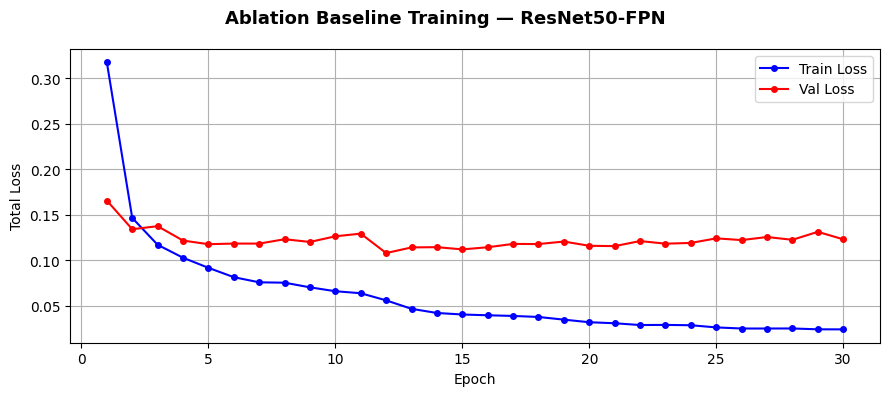

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_baseline_training__resnet50-fpn.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_baseline_training__resnet50-fpn.csv

═════════════════════════════════════════════════════════════════
  Strategy: Random pruning
═════════════════════════════════════════════════════════════════


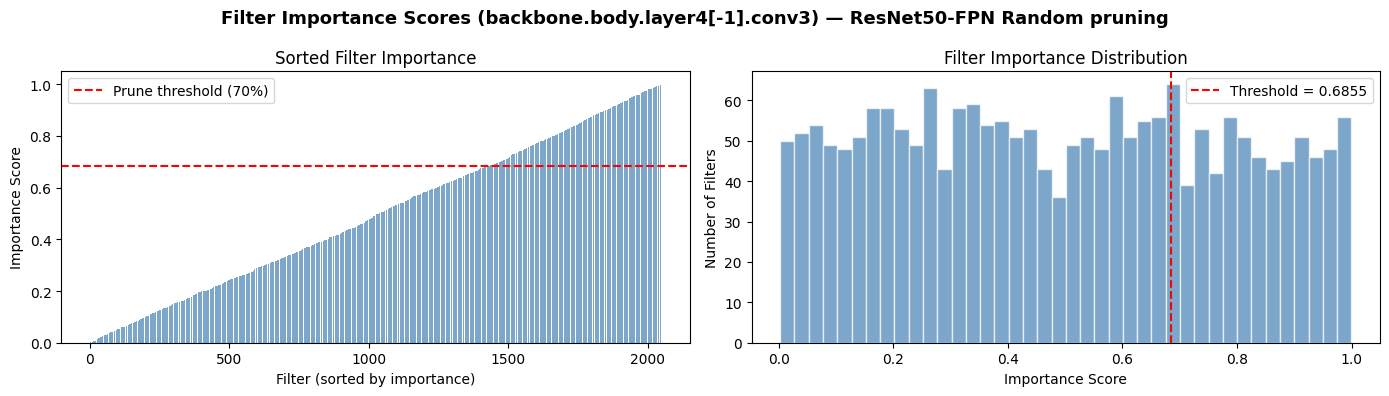

Filter importance plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_random.png
Filter importance CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_random.csv
Filters to prune: 1433 / 2048

Masked channel pruning on backbone.body.layer4[-1].conv3
  Total filters:  2048
  Pruning:        1433 (70%)
  Keeping:        615

Training [resnet50_fpn_ablation_random] for 10 epochs on cuda...
Epoch [01/10]  Train: 0.0667  Val: 0.1305  Time: 16.4s ✓ Best
Epoch [02/10]  Train: 0.0649  Val: 0.1170  Time: 16.9s ✓ Best
Epoch [03/10]  Train: 0.0548  Val: 0.1306  Time: 17.2s
Epoch [04/10]  Train: 0.0538  Val: 0.1267  Time: 13.0s
Epoch [05/10]  Train: 0.0591  Val: 0.1261  Time: 13.0s
Epoch [06/10]  Train: 0.0521  Val: 0.1215  Time: 13.1s
Epoch [07/10]  Train: 0.0473  Val: 0.1283  Time: 13.1s
Epoch [08/10]  Train: 0.0509  Val: 0.1250  Time: 13.0s
Epoch [09/10]  Train: 0.0436  Val: 0.1147  Tim

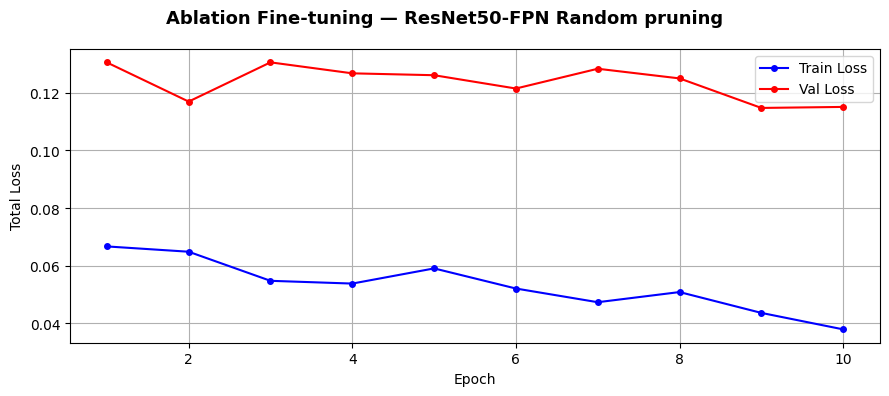

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_random_pruning.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_random_pruning.csv

═════════════════════════════════════════════════════════════════
  Strategy: Activation-only pruning
═════════════════════════════════════════════════════════════════
Hybrid Activation-Taylor importance computed over 20 batches.
Layer: backbone.body.layer4[-1].conv3 | Filters: 2048
Weights: activation=0.50, Taylor=0.50


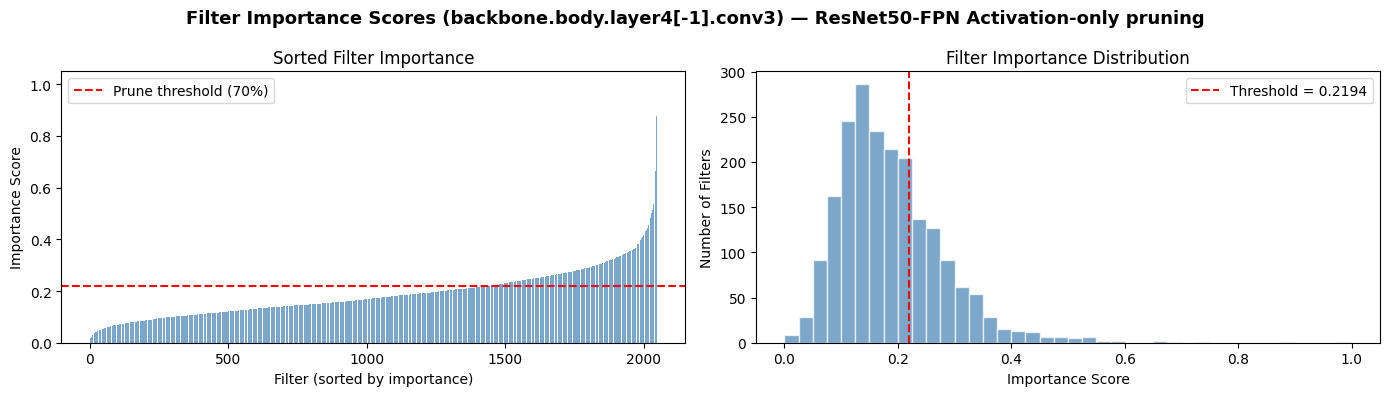

Filter importance plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_activation.png
Filter importance CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_activation.csv
Filters to prune: 1433 / 2048

Masked channel pruning on backbone.body.layer4[-1].conv3
  Total filters:  2048
  Pruning:        1433 (70%)
  Keeping:        615

Training [resnet50_fpn_ablation_activation] for 10 epochs on cuda...
Epoch [01/10]  Train: 0.0688  Val: 0.1361  Time: 13.0s ✓ Best
Epoch [02/10]  Train: 0.0627  Val: 0.1147  Time: 17.4s ✓ Best
Epoch [03/10]  Train: 0.0562  Val: 0.1193  Time: 17.3s
Epoch [04/10]  Train: 0.0543  Val: 0.1169  Time: 13.0s
Epoch [05/10]  Train: 0.0559  Val: 0.1285  Time: 13.0s
Epoch [06/10]  Train: 0.0503  Val: 0.1361  Time: 12.9s
Epoch [07/10]  Train: 0.0478  Val: 0.1127  Time: 13.0s ✓ Best
Epoch [08/10]  Train: 0.0459  Val: 0.1195  Time: 16.7s
Epoch [09/10]  Train: 0.045

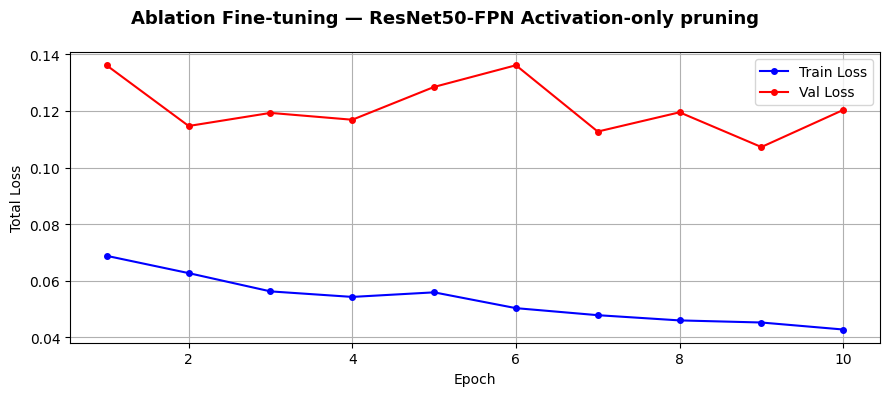

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_activation-only_pruning.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_activation-only_pruning.csv

═════════════════════════════════════════════════════════════════
  Strategy: Taylor-only pruning
═════════════════════════════════════════════════════════════════
Hybrid Activation-Taylor importance computed over 20 batches.
Layer: backbone.body.layer4[-1].conv3 | Filters: 2048
Weights: activation=0.50, Taylor=0.50


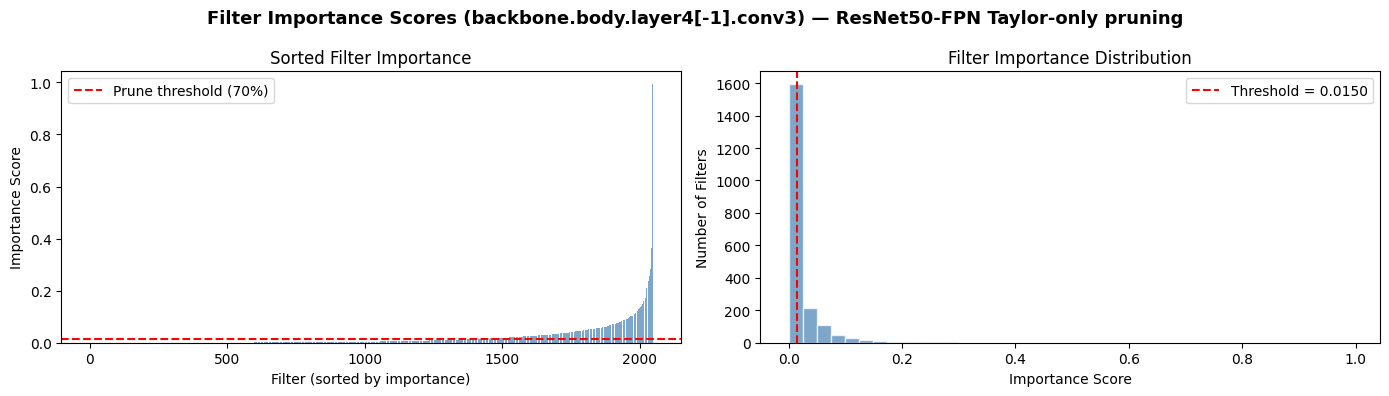

Filter importance plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_taylor.png
Filter importance CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_taylor.csv
Filters to prune: 1433 / 2048

Masked channel pruning on backbone.body.layer4[-1].conv3
  Total filters:  2048
  Pruning:        1433 (70%)
  Keeping:        615

Training [resnet50_fpn_ablation_taylor] for 10 epochs on cuda...
Epoch [01/10]  Train: 0.0684  Val: 0.1775  Time: 13.1s ✓ Best
Epoch [02/10]  Train: 0.0665  Val: 0.1223  Time: 16.8s ✓ Best
Epoch [03/10]  Train: 0.0577  Val: 0.1160  Time: 16.4s ✓ Best
Epoch [04/10]  Train: 0.0533  Val: 0.1409  Time: 16.8s
Epoch [05/10]  Train: 0.0520  Val: 0.1334  Time: 12.9s
Epoch [06/10]  Train: 0.0487  Val: 0.1245  Time: 13.0s
Epoch [07/10]  Train: 0.0517  Val: 0.1333  Time: 13.0s
Epoch [08/10]  Train: 0.0501  Val: 0.1291  Time: 13.1s
Epoch [09/10]  Train: 0.0500  Val: 0.12

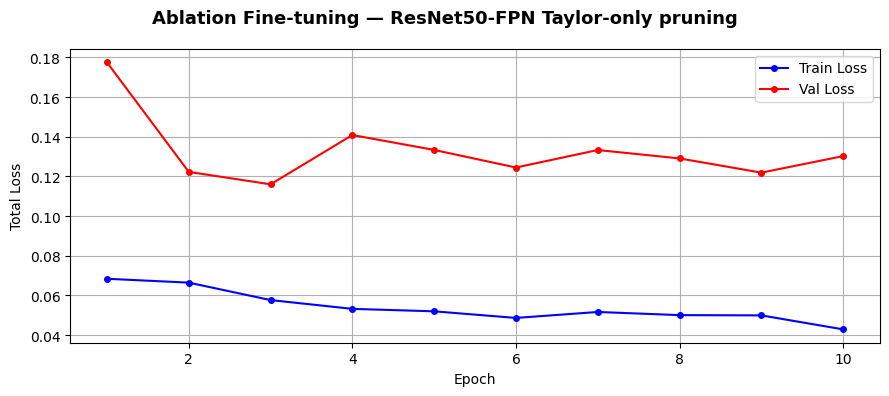

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_taylor-only_pruning.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_taylor-only_pruning.csv

═════════════════════════════════════════════════════════════════
  Strategy: Loss-guided XAI Grad-CAM relevance pruning
═════════════════════════════════════════════════════════════════
Loss-guided XAI Grad-CAM relevance importance computed over 20 batches.
Layer: backbone.body.layer4[-1].conv3 | Filters: 2048


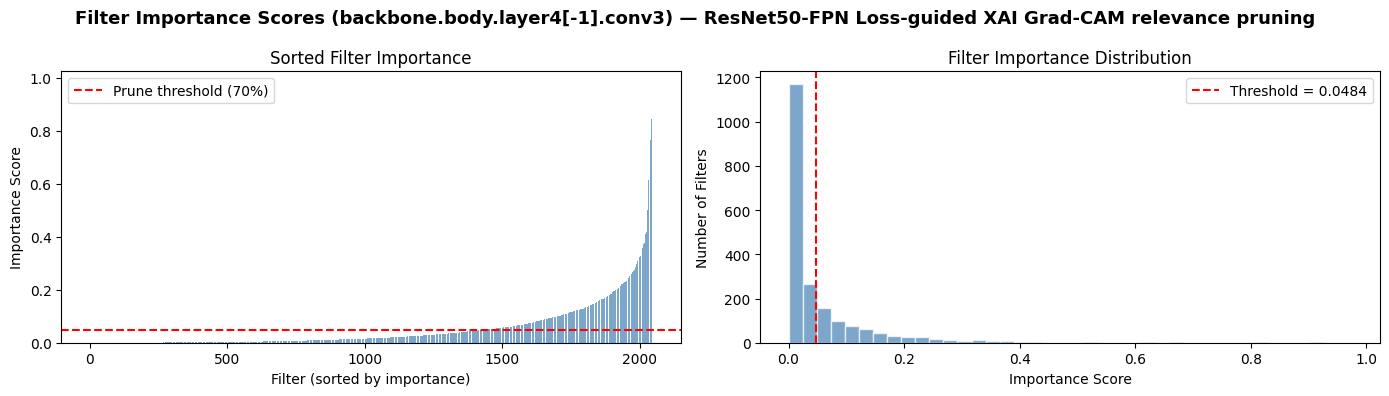

Filter importance plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_xai_gradcam.png
Filter importance CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_xai_gradcam.csv
Filters to prune: 1433 / 2048


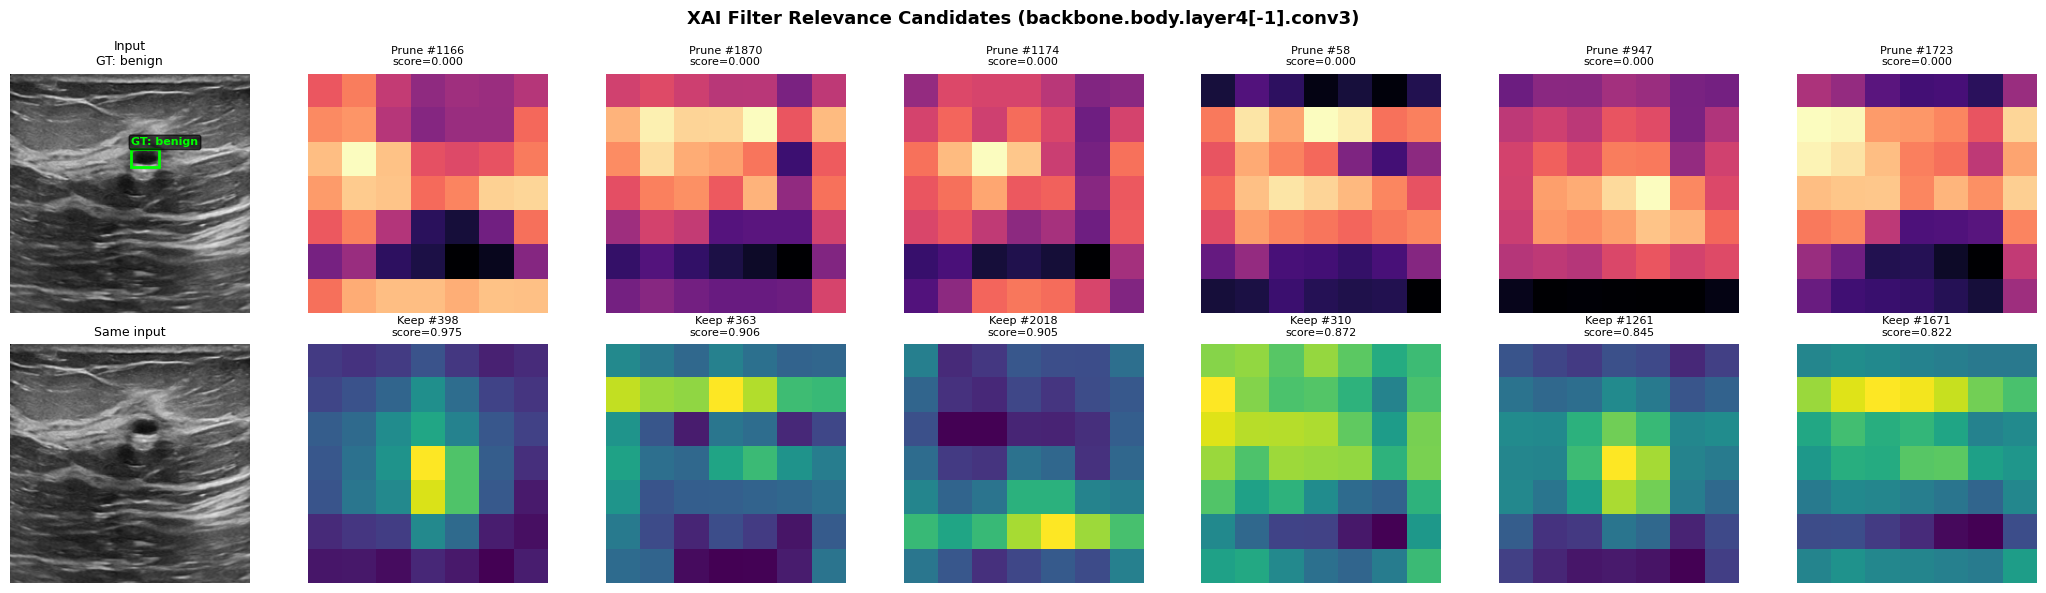

XAI filter pruning candidate visualization saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/gradcam_outputs/resnet50_fpn_ablation_xai_gradcam_xai_filter_candidates.png

Masked channel pruning on backbone.body.layer4[-1].conv3
  Total filters:  2048
  Pruning:        1433 (70%)
  Keeping:        615

Training [resnet50_fpn_ablation_xai_gradcam] for 10 epochs on cuda...
Epoch [01/10]  Train: 0.0693  Val: 0.1399  Time: 12.9s ✓ Best
Epoch [02/10]  Train: 0.0579  Val: 0.1427  Time: 16.6s
Epoch [03/10]  Train: 0.0571  Val: 0.1087  Time: 12.9s ✓ Best
Epoch [04/10]  Train: 0.0509  Val: 0.1127  Time: 13.1s
Epoch [05/10]  Train: 0.0489  Val: 0.1247  Time: 13.0s
Epoch [06/10]  Train: 0.0532  Val: 0.1469  Time: 12.9s
Epoch [07/10]  Train: 0.0528  Val: 0.1160  Time: 13.0s
Epoch [08/10]  Train: 0.0540  Val: 0.1207  Time: 12.9s
Epoch [09/10]  Train: 0.0538  Val: 0.1282  Time: 12.9s
Epoch [10/10]  Train: 0.0430  Val: 0.1211  Time: 13.0s

✓ [resnet50_fpn_ablation_xai_gradcam] done.  Best Val Los

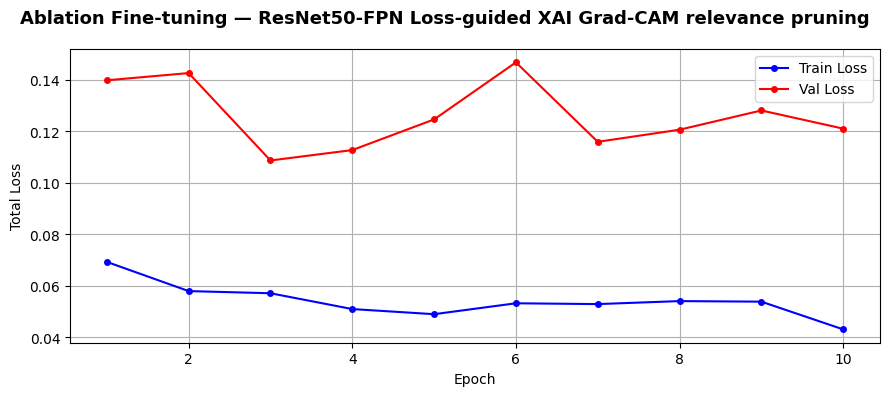

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_loss-guided_xai_grad-cam_relevance_pruning.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_loss-guided_xai_grad-cam_relevance_pruning.csv

═════════════════════════════════════════════════════════════════
  Strategy: Hybrid activation-Taylor pruning
═════════════════════════════════════════════════════════════════
Hybrid Activation-Taylor importance computed over 20 batches.
Layer: backbone.body.layer4[-1].conv3 | Filters: 2048
Weights: activation=0.50, Taylor=0.50


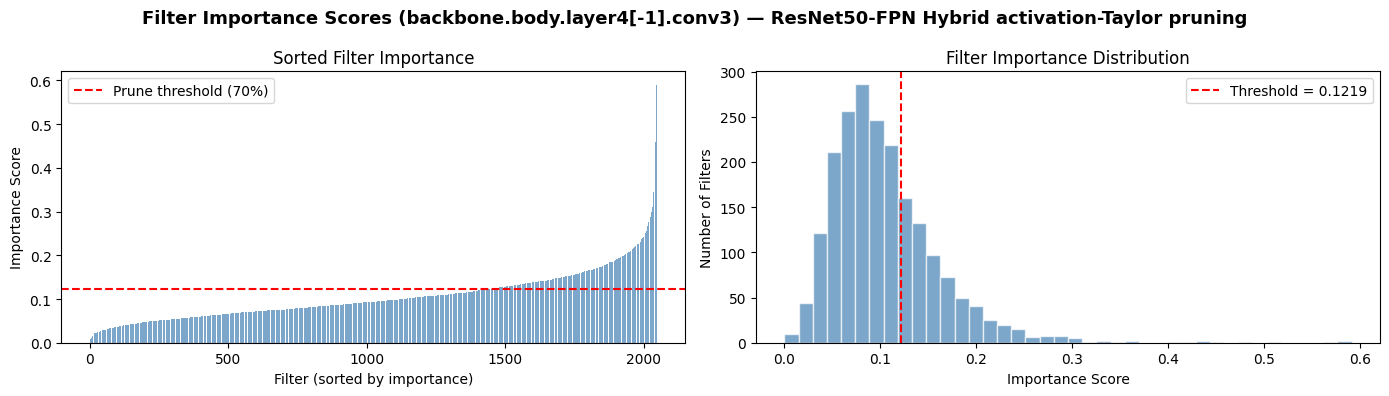

Filter importance plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_hybrid.png
Filter importance CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/filter_importance_resnet50_fpn_ablation_hybrid.csv
Filters to prune: 1433 / 2048

Masked channel pruning on backbone.body.layer4[-1].conv3
  Total filters:  2048
  Pruning:        1433 (70%)
  Keeping:        615

Training [resnet50_fpn_ablation_hybrid] for 10 epochs on cuda...
Epoch [01/10]  Train: 0.0652  Val: 0.1260  Time: 13.0s ✓ Best
Epoch [02/10]  Train: 0.0590  Val: 0.1308  Time: 16.7s
Epoch [03/10]  Train: 0.0576  Val: 0.1334  Time: 13.0s
Epoch [04/10]  Train: 0.0561  Val: 0.1243  Time: 13.0s ✓ Best
Epoch [05/10]  Train: 0.0545  Val: 0.1247  Time: 13.0s
Epoch [06/10]  Train: 0.0525  Val: 0.1289  Time: 13.0s
Epoch [07/10]  Train: 0.0500  Val: 0.1406  Time: 13.0s
Epoch [08/10]  Train: 0.0458  Val: 0.1331  Time: 12.9s
Epoch [09/10]  Train: 0.0459  Val: 0.1530  Tim

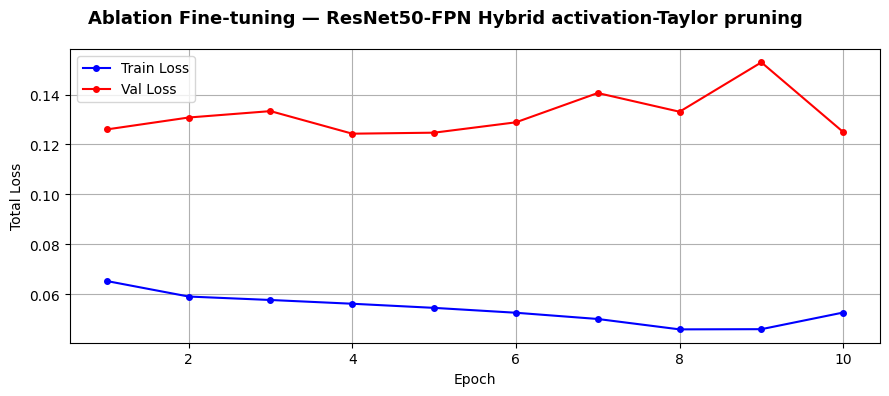

Training history plot saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_hybrid_activation-taylor_pruning.png
Training history CSV saved  → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/ablation_fine-tuning__resnet50-fpn_hybrid_activation-taylor_pruning.csv

── Pruning Strategy Evaluation on Test Set ──

  ResNet50-FPN No pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.7390
  mAP@0.75:  0.5991

  Per-class AP@0.50:
    benign      : 0.7634
    malignant   : 0.5889
    normal      : 0.8648

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9661    0.9344    0.9500        61
   malignant     0.8400    0.9130    0.8750        23
      normal     1.0000    1.0000    1.0000        20

    accuracy                         0.9423       104
   macro avg     0.9354    0.9492    0.9417       104
weighted avg     0.9447    0.9423    0.9430       104



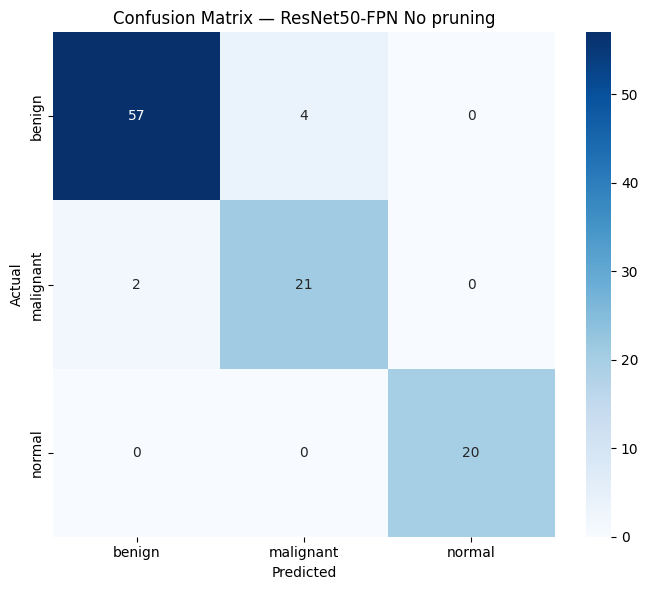

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_no_pruning.png

  ResNet50-FPN Random pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.7076
  mAP@0.75:  0.5891

  Per-class AP@0.50:
    benign      : 0.7795
    malignant   : 0.5303
    normal      : 0.8131

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9344    0.9661    0.9500        59
   malignant     0.8947    0.8095    0.8500        21
      normal     1.0000    1.0000    1.0000        18

    accuracy                         0.9388        98
   macro avg     0.9431    0.9252    0.9333        98
weighted avg     0.9380    0.9388    0.9378        98



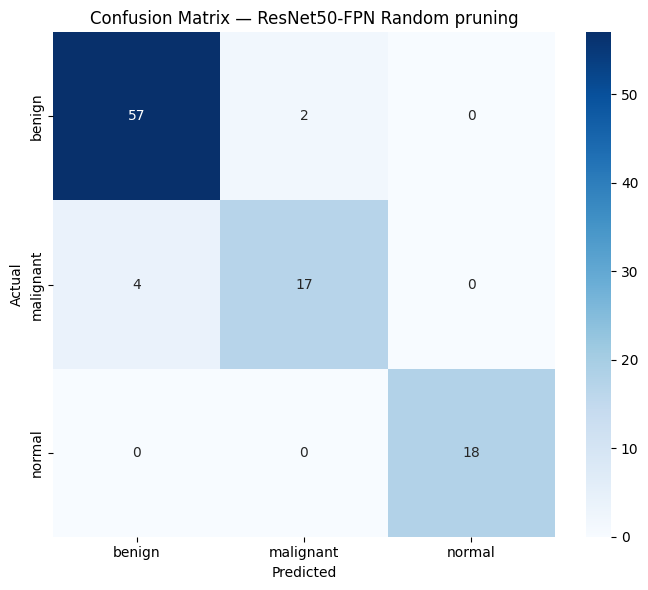

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_random_pruning.png

  ResNet50-FPN Activation-only pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.7079
  mAP@0.75:  0.6083

  Per-class AP@0.50:
    benign      : 0.7701
    malignant   : 0.4760
    normal      : 0.8777

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9167    0.9483    0.9322        58
   malignant     0.8421    0.7619    0.8000        21
      normal     1.0000    1.0000    1.0000        19

    accuracy                         0.9184        98
   macro avg     0.9196    0.9034    0.9107        98
weighted avg     0.9168    0.9184    0.9170        98



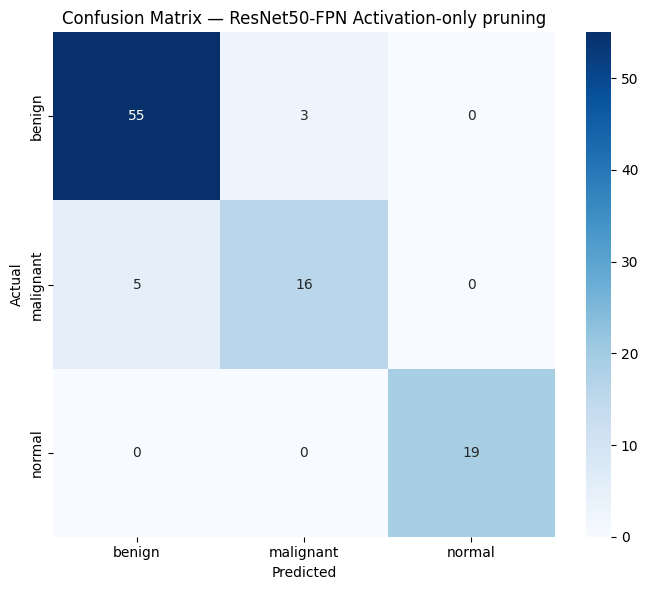

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_activation-only_pruning.png

  ResNet50-FPN Taylor-only pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.7311
  mAP@0.75:  0.5708

  Per-class AP@0.50:
    benign      : 0.7635
    malignant   : 0.5558
    normal      : 0.8742

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9643    0.9000    0.9310        60
   malignant     0.7692    0.9091    0.8333        22
      normal     1.0000    1.0000    1.0000        20

    accuracy                         0.9216       102
   macro avg     0.9112    0.9364    0.9215       102
weighted avg     0.9292    0.9216    0.9235       102



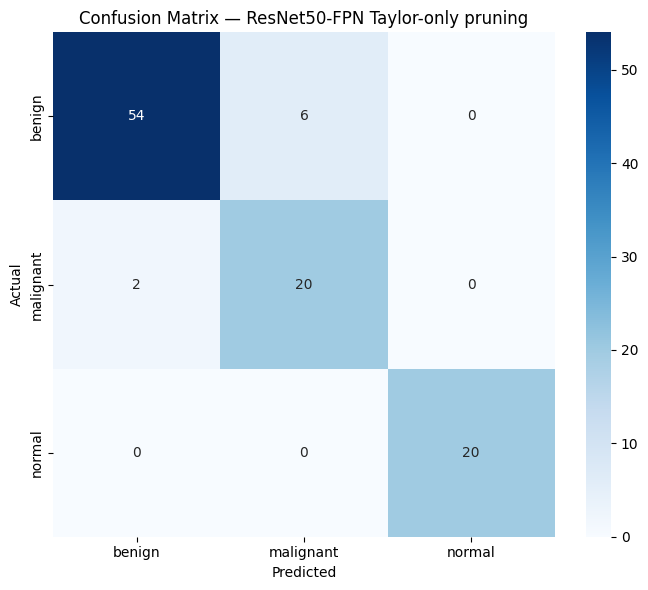

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_taylor-only_pruning.png

  ResNet50-FPN Loss-guided XAI Grad-CAM relevance pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.6955
  mAP@0.75:  0.5668

  Per-class AP@0.50:
    benign      : 0.7829
    malignant   : 0.4711
    normal      : 0.8324

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9375    0.9836    0.9600        61
   malignant     0.9375    0.7895    0.8571        19
      normal     1.0000    1.0000    1.0000        19

    accuracy                         0.9495        99
   macro avg     0.9583    0.9244    0.9390        99
weighted avg     0.9495    0.9495    0.9479        99



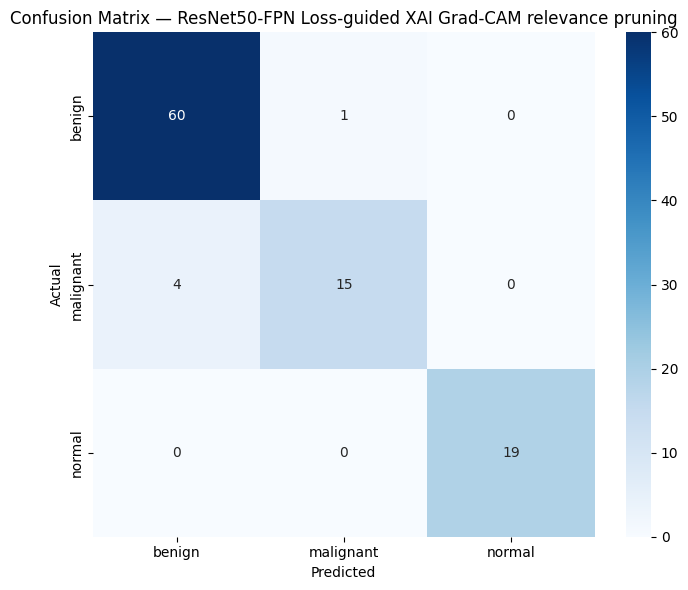

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_loss-guided_xai_grad-cam_relevance_pruning.png

  ResNet50-FPN Hybrid activation-Taylor pruning Evaluation — Faster R-CNN
  mAP@0.50:  0.7164
  mAP@0.75:  0.5634

  Per-class AP@0.50:
    benign      : 0.7762
    malignant   : 0.5160
    normal      : 0.8570

  Classification Report (matched detections):
              precision    recall  f1-score   support

      benign     0.9508    0.9831    0.9667        59
   malignant     0.9474    0.8571    0.9000        21
      normal     1.0000    1.0000    1.0000        20

    accuracy                         0.9600       100
   macro avg     0.9661    0.9467    0.9556       100
weighted avg     0.9599    0.9600    0.9593       100



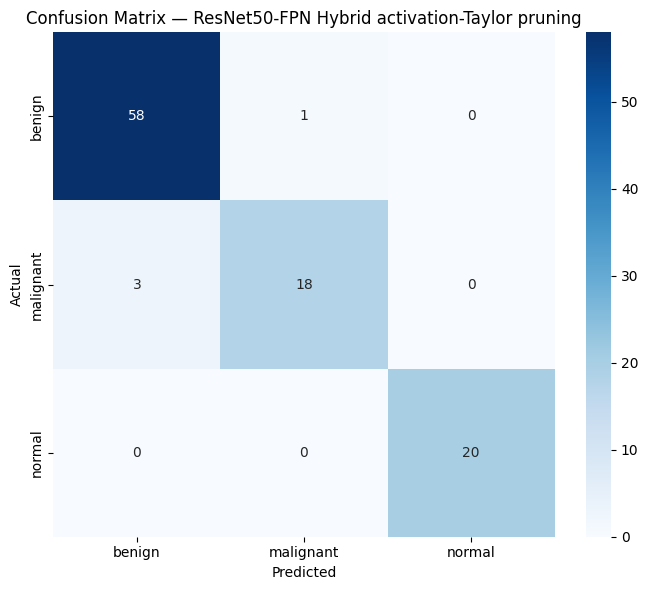

Confusion matrix saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/plots/confusion_matrix_resnet50-fpn_hybrid_activation-taylor_pruning.png

  Inference Speed Benchmark  (50 runs, single image)
  Model                         Mean (ms)   Std (ms)
  ----------------------------------------------------
  No pruning                       24.52       0.31
  Random pruning                   24.71       0.40
  Activation-only pruning          25.20       0.27
  Taylor-only pruning              24.85       0.31
  Loss-guided XAI Grad-CAM relevance pruning     24.46       0.23
  Hybrid activation-Taylor pruning     25.10       0.31

  Model                              Params     vs Base
  --------------------------------------------------------
  No pruning                     41,309,411      (base)
  Random pruning                 40,572,849      -1.78%
  Activation-only pruning        40,572,849      -1.78%
  Taylor-only pruning            40,572,849      -1.78%
  Loss-guided XAI Grad

/tmp/ipykernel_10148/1588622364.py:873: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


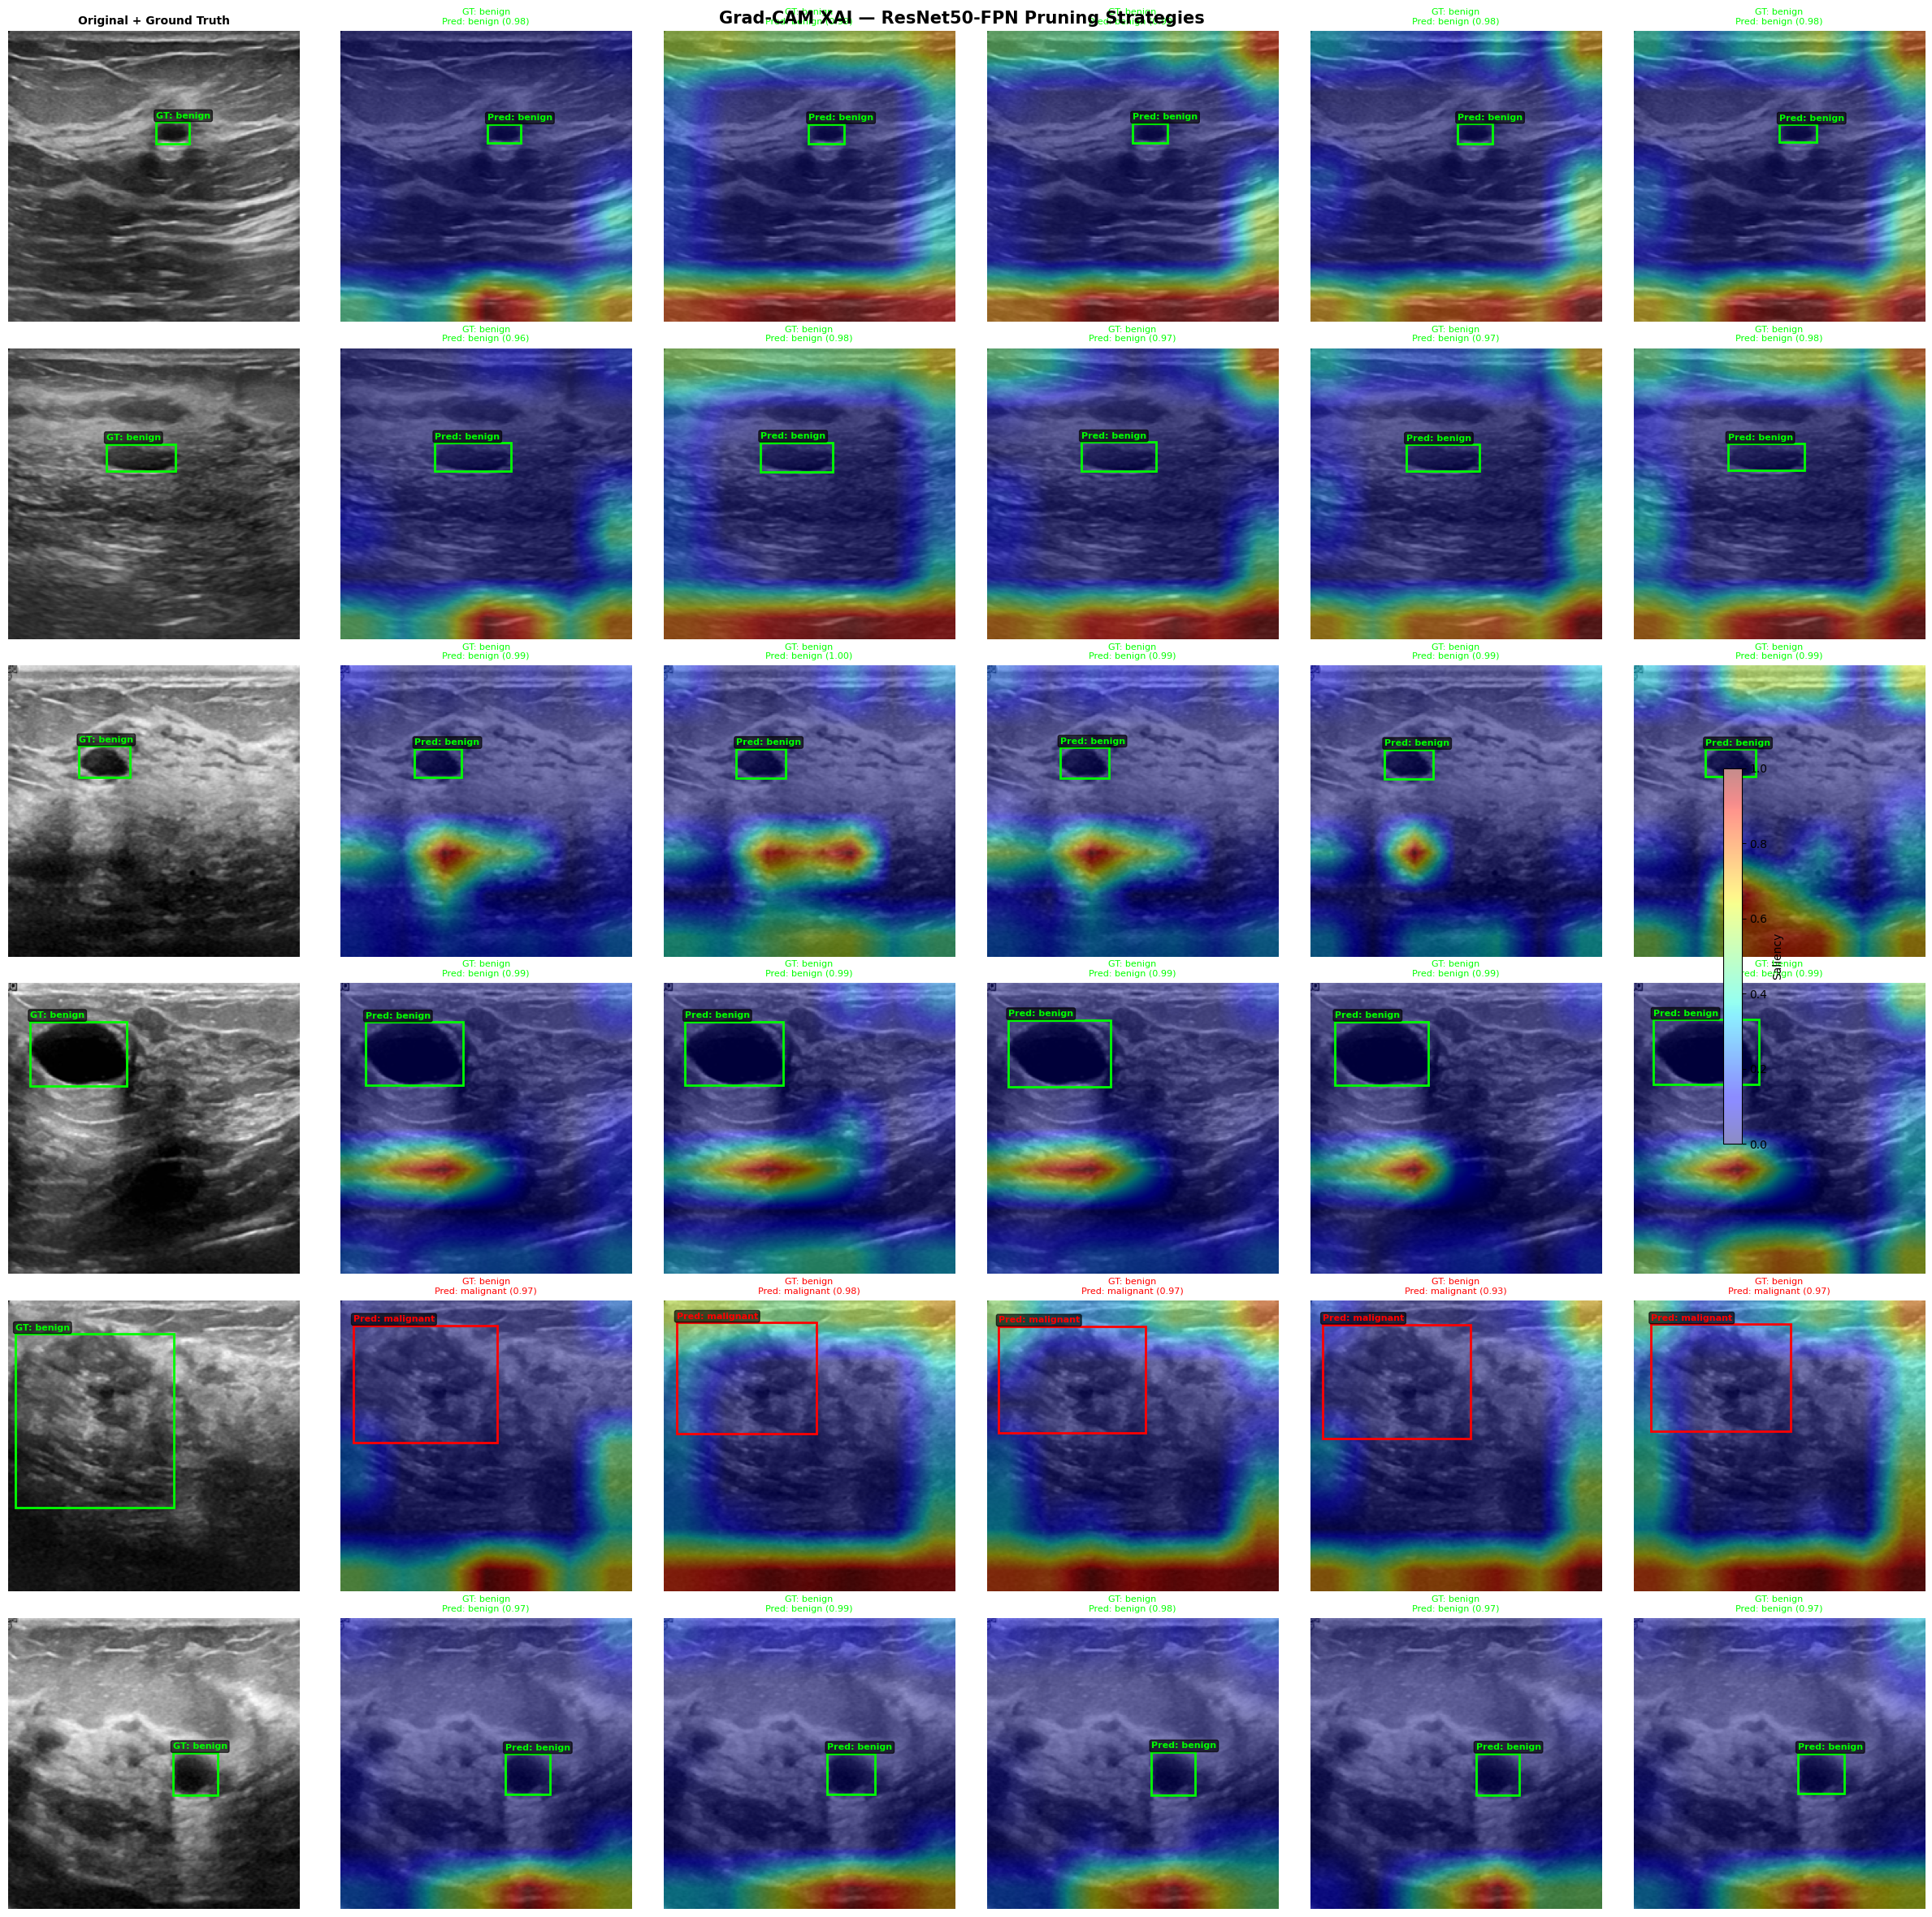

Grad-CAM comparison saved → /content/drive/MyDrive/FYP5V4_resnet50_ablation/gradcam_outputs/resnet50_fpn_pruning_strategy_gradcam.png

████████████████████████████████████████████████████████████████████████
  RESNET50-FPN PRUNING STRATEGY ABLATION SUMMARY
████████████████████████████████████████████████████████████████████████
  Strategy                                             mAP@0.50   mAP@0.75  Precision     Recall       F1         Params    ms/img
  --------------------------------------------------------------------------------------------------------------------------------------
  No pruning                                             0.7390     0.5991     0.9447     0.9423   0.9430     41,309,411     24.52
  Random pruning                                         0.7076     0.5891     0.9380     0.9388   0.9378     40,572,849     24.71
  Activation-only pruning                                0.7079     0.6083     0.9168     0.9184   0.9170     40,572,849     25.20
  Taylor-

In [ ]:
terminal_log_path = start_terminal_logging()
print('\n' + '█' * 72)
print('  RESNET50-FPN PRUNING ABLATION ONLY')
print('█' * 72)
print('  Backbone: fasterrcnn_resnet50_fpn / ResNet50-FPN')
print('  Strategies: no pruning, random, activation-only, Taylor-only,')
print('              hybrid activation-Taylor, loss-guided XAI Grad-CAM relevance')

ablation_results = run_pruning_strategy_ablation(
    backbone_name=CONFIG['ablation_backbone'],
    backbone_label=CONFIG['ablation_backbone_label'],
    trained_base_model=None
)

print('\n' + '█' * 72)
print('  RESNET50-FPN PRUNING STRATEGY ABLATION SUMMARY')
print('█' * 72)
print(f'  {"Strategy":<50} {"mAP@0.50":>10} {"mAP@0.75":>10} {"Precision":>10} {"Recall":>10} {"F1":>8} {"Params":>14} {"ms/img":>9}')
print(f'  {"-" * 134}')
for row in ablation_results['rows']:
    print(f'  {row["strategy"]:<50} '
          f'{row["mAP@0.50"]:>10.4f} '
          f'{row["mAP@0.75"]:>10.4f} '
          f'{row["precision"]:>10.4f} '
          f'{row["recall"]:>10.4f} '
          f'{row["F1-score"]:>8.4f} '
          f'{int(row["effective_params"]):>14,} '
          f'{row["inference_ms_per_image"]:>9.2f}')

print('\nProject framing note:')
print('This focused script evaluates pruning criteria on fasterrcnn_resnet50_fpn only.')
print('The loss-guided XAI Grad-CAM-style score is an application-specific relevance proxy, not a claim of a new Grad-CAM theory.')

